# Probability of Default (PD) Modeling – Loan Risk Assessment

### Objective
The primary objective of this project is to develop a robust binary classification machine learning model to estimate the Probability of Default (PD) for loan applicants. By leveraging demographic, financial, and credit history features, the model will classify borrowers into 'Default' (1) or 'Repaid' (0) categories. The insights gained will support credit decisioning, risk-based pricing, and proactive risk management to minimize potential losses for the financial institution.

### Business Context
Loan default poses a significant threat to the financial stability of lending institutions. A reliable PD model enables a bank to make informed decisions by:
* **Assessing Risk**: Accurately quantifying the risk associated with each loan applicant.
* **Risk-Based Pricing**: Setting appropriate interest rates and loan terms that reflect the borrower's risk profile.
* **Portfolio Management**: Monitoring the risk exposure of the entire loan portfolio and identifying segments requiring early intervention.

### Methodology
This project will follow a structured machine learning workflow:
1.  **Data Understanding & Cleaning**: Initial exploration, handling missing values, and addressing outliers.
2.  **Exploratory Data Analysis (EDA)**: Visualizing distributions and relationships between features to uncover key insights.
3.  **Feature Engineering**: Creating new, meaningful features to enhance model performance.
4.  **Model Building & Evaluation**: Training and evaluating several classification models, including a baseline and an advanced tree-based model, using a range of appropriate metrics for imbalanced datasets.
5.  **Model Explainability**: Interpreting model predictions to understand the key drivers of default risk.
6.  **PD Calibration**: Calibrating the model's probability outputs to ensure they accurately reflect real-world default rates.
7.  **Risk-Based Strategy Simulation**: Simulating business strategies based on the model's output to demonstrate its practical application and potential business impact.
8.  **Recommendation**: Providing strategic recommendations for integrating the model into existing credit polring the data cleaning phase.

### Import necessary libraries

In [1]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# %matplotlib inline
# import seaborn as sns
# import plotly.express as px

# 0. Create Custom bank dataset

### Dataset Column Descriptions

| Column | Description |
|--------|-------------|
| `age` | Borrower's age (22–65), simulated using a **beta distribution** to reflect a skewed adult population. |
| `gender` | Randomly assigned gender with realistic probabilities: **Male (55%)**, **Female (44%)**, **Other (1%)**. |
| `marital_status` | Random marital status: **Single, Married, Divorced**, weighted toward Married and Single. |
| `employment_status` | Employment status chosen with realistic distribution: **Employed (70%)**, **Self-Employed (25%)**, **Unemployed (5%)**. |
| `housing_status` | Simulated housing condition, with random mix and inconsistent casing for added data cleaning challenges. |
| `credit_score` | Normally distributed credit score (mean=700, std=85), **clipped between 300 and 850** to match real FICO range. |
| `income` | Annual income drawn from a **log-normal distribution**, based on state averages and adjusted for employment status. |
| `expenses` | Monthly expenses calculated as a **ratio of income**, using a beta distribution to reflect varying spending habits. |
| `loan_amount` | Loan size determined as a **proportion of income** plus a base noise term, capped between \$500 and \$75,000. |
| `debt_to_income` | DTI ratio computed as **(expenses + noise) / monthly income**, capped between 0.05 and 0.6; **set to 0.6 for unemployed**. |
| `term` | Loan term randomly selected as either **36 or 60 months**, with a 70% preference for shorter term. |
| `interest_rate` | Base rate tied to **credit score and economic cycle**, with random noise added, bounded between 4.5% and 29%. |
| `collateral` | Binary indicator whether loan is collateralized (**1 = Yes, 0 = No**), with 20% chance of having collateral. |
| `loan_purpose` | Purpose of the loan (e.g., debt_consolidation, credit_card, small_business), sampled with realistic frequencies. |
| `loan_title` | Text description generated using **Faker** and loan purpose, mimicking free-text input in real applications. |
| `delinquencies` | Number of past credit delinquencies, sampled from a **Poisson distribution** with λ=0.8. |
| `inquiries` | Count of recent credit inquiries, also sampled from **Poisson(1.5)**, representing recent credit-seeking activity. |
| `credit_history_length_months` | Random number of months since credit history started, **capped by age** to keep logic intact. |
| `application_date` | Simulated application date between 2023 and 2024, used to model **economic cycles**. |
| `economic_cycle` | Label ('Stable' or 'Stressed') based on application year: **2024 = Stressed**, 2023 = Stable. |
| `state` | U.S. state of residence (CA, NY, TX, FL, IL), randomly sampled with equal probability. |
| `default` | **Binary target** (0 = repaid, 1 = defaulted), derived using a **weighted sum of risk features** + noise, then sampled as a probability. |


In [2]:
# from faker import Faker
# import random
# from datetime import datetime, timedelta

# # --- Initialization ---
# fake = Faker('en_US')
# np.random.seed(42)
# random.seed(42)
# num_applications = 50000

# # --- Application Dates & Economic Cycle ---
# start_date = datetime(2023, 1, 1)
# application_dates = [start_date + timedelta(days=random.randint(0, 730)) for _ in range(num_applications)]
# df_dates = pd.DataFrame(application_dates, columns=['application_date'])

# def get_economic_cycle(date):
#     if date.year == 2023:
#         return 'Stable'
#     elif date.year == 2024:
#         return 'Stressed'
#     return 'Stable'

# df_dates['economic_cycle'] = df_dates['application_date'].apply(get_economic_cycle)

# # --- Demographics ---
# age = (np.random.beta(a=3, b=5, size=num_applications) * 45 + 22).astype(int)
# age = np.clip(age, 22, 65)

# gender = np.random.choice(['Male', 'Female', 'Other'], num_applications, p=[0.55, 0.44, 0.01])
# marital_status = np.random.choice(['Single', 'Married', 'Divorced'], num_applications, p=[0.45, 0.5, 0.05])
# housing_status = np.char.capitalize(np.random.choice(['rent', 'own', 'mortgage', 'RENT', 'Rent'], num_applications, p=[0.3, 0.2, 0.4, 0.05, 0.05]))
# employment_status = np.random.choice(['Employed', 'Self-Employed', 'Unemployed'], num_applications, p=[0.7, 0.25, 0.05])
# state = np.random.choice(['CA', 'NY', 'TX', 'FL', 'IL'], num_applications)

# # --- Financials ---
# income_by_state = {'CA': 100000, 'NY': 95000, 'TX': 75000, 'FL': 70000, 'IL': 80000}
# income_base = np.array([income_by_state[s] for s in state])
# income = np.random.lognormal(mean=np.log(income_base), sigma=0.8)
# income[employment_status == 'Unemployed'] = 0
# income[employment_status == 'Self-Employed'] *= np.random.lognormal(mean=0, sigma=0.2, size=(employment_status == 'Self-Employed').sum())
# income = income.round(2)

# expenses_ratio = np.random.beta(a=2, b=5, size=num_applications)
# expenses = (income / 12 * expenses_ratio).round(2)

# loan_amount = (np.random.uniform(0.1, 0.5, num_applications) * income + np.random.uniform(500, 5000, size=num_applications))
# loan_amount = np.clip(loan_amount, 500, 75000).astype(int)

# # --- Loan Details ---
# term = np.random.choice([36, 60], num_applications, p=[0.7, 0.3])
# collateral = np.random.choice([0, 1], num_applications, p=[0.8, 0.2])
# loan_purpose_options = ['debt_consolidation', 'credit_card', 'home_improvement', 'other', 'major_purchase', 'medical', 'small_business']
# loan_purpose = np.random.choice(loan_purpose_options, num_applications, p=[0.45, 0.2, 0.1, 0.1, 0.05, 0.05, 0.05])
# loan_title = [f"{p} loan for {fake.word()}" if random.random() < 0.7 else f"{p.capitalize()}." for p in loan_purpose]

# # --- Credit History ---
# credit_score = np.random.normal(loc=700, scale=85, size=num_applications).astype(int)
# credit_score = np.clip(credit_score, 300, 850)
# delinquencies = np.random.poisson(lam=0.8, size=num_applications)
# inquiries = np.random.poisson(lam=1.5, size=num_applications)

# max_history = (age - 20) * 12
# max_history = np.clip(max_history, 12, None)
# credit_history_length_months = np.array([random.randint(1, int(m)) for m in max_history])

# # --- Interest Rate ---
# interest_rate_base = 20 - (credit_score / 850) * 15
# interest_rate_eco_factor = np.where(df_dates['economic_cycle'] == 'Stressed', 3, 0)
# interest_rate = interest_rate_base + interest_rate_eco_factor + np.random.normal(0, 2, num_applications)
# interest_rate = np.clip(interest_rate, 4.5, 29).round(2)

# # --- DTI & Target ---
# monthly_income = income / 12
# monthly_income[monthly_income == 0] = np.nan  # Avoid divide-by-zero

# debt_to_income = (expenses + np.random.uniform(0, 500, size=num_applications)) / monthly_income
# debt_to_income = np.clip(debt_to_income, 0.05, 0.6).round(4)
# debt_to_income[employment_status == 'Unemployed'] = 0.6

# # --- Default Logic (Target Variable) ---
# default_prob_base = 0.08
# default_prob_factors = (
#     (debt_to_income / np.nanmean(debt_to_income)) * 0.22 +
#     (1 - (credit_score / 850)) * 0.35 +
#     (inquiries / np.max(inquiries)) * 0.15 +
#     (delinquencies / np.max(delinquencies)) * 0.2 -
#     (credit_history_length_months / np.max(credit_history_length_months)) * 0.07 -
#     (collateral * 0.1) +
#     np.where(loan_purpose == 'small_business', 0.12, 0) +
#     np.where(employment_status == 'Unemployed', 0.3, 0) +
#     np.where(df_dates['economic_cycle'] == 'Stressed', 0.07, 0)
# )

# default_prob = default_prob_base + default_prob_factors + np.random.normal(0, 0.05, size=num_applications)
# default_prob = np.clip(default_prob, 0.01, 0.99)
# default = (np.random.rand(num_applications) < default_prob).astype(int)

# # --- Assemble Dataset ---
# df = pd.DataFrame({
#     'age': age, 'gender': gender, 'marital_status': marital_status, 'employment_status': employment_status,
#     'housing_status': housing_status, 'credit_score': credit_score, 'income': income, 'expenses': expenses,
#     'loan_amount': loan_amount, 'debt_to_income': debt_to_income, 'term': term, 'interest_rate': interest_rate,
#     'collateral': collateral, 'loan_purpose': loan_purpose, 'loan_title': loan_title, 'delinquencies': delinquencies,
#     'inquiries': inquiries, 'credit_history_length_months': credit_history_length_months,
#     'application_date': df_dates['application_date'], 'economic_cycle': df_dates['economic_cycle'],
#     'state': state, 'default': default
# })

# # --- Inject Outliers ---
# outlier_indices = np.random.choice(df.index, size=20, replace=False)
# df.loc[outlier_indices, 'income'] *= 10
# df.loc[outlier_indices, 'debt_to_income'] *= 3
# df.loc[outlier_indices, 'credit_score'] = 300

# # --- Independent Missing Values ---
# missing_config = {
#     'income': 0.043,
#     'expenses': 0.032,
#     'debt_to_income': 0.151,
#     'credit_history_length_months': 0.021,
# }

# for col, ratio in missing_config.items():
#     n_missing = int(ratio * num_applications)
#     null_indices = np.random.choice(df.index, size=n_missing, replace=False)
#     df.loc[null_indices, col] = np.nan

# # Duplicated values
# num_duplicates = 500  # 1% of 50,000

# duplicate_indices = np.random.choice(df.index, size=num_duplicates, replace=False)
# df.loc[np.random.choice(df.index, size=num_duplicates, replace=False)] = df.loc[duplicate_indices].values

# df.to_csv('loan.csv', index=False)

In [3]:
# pd.set_option('display.max_columns', None)

In [4]:
# df.head()

# 1. Data Understanding & Cleaning

#### 1.1 Load Data and Initial Inspection

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import plotly.express as px

In [6]:
pd.set_option('display.max_columns', None)

In [7]:
df=pd.read_csv('loan.csv')

In [8]:
df.head()

,age,gender,marital_status,employment_status,housing_status,credit_score,income,expenses,loan_amount,debt_to_income,term,interest_rate,collateral,loan_purpose,loan_title,delinquencies,inquiries,credit_history_length_months,application_date,economic_cycle,state,default
0,42,Female,Married,Self-Employed,Mortgage,756,150844.62,6813.44,74798,0.5494,36,14.29,0,credit_card,Credit_card.,0,2,4.0,2024-10-16,Stressed,NY,0
1,37,Female,Married,Unemployed,Mortgage,649,NaN,0.00,3499,0.6000,36,8.17,1,debt_consolidation,debt_consolidation loan for memory,1,2,171.0,2023-04-25,Stable,IL,1
2,43,Female,Married,Employed,Rent,594,54073.89,754.31,20101,0.1703,36,8.53,0,debt_consolidation,debt_consolidation loan for support,0,3,170.0,2023-01-26,Stable,FL,1
3,33,Male,Married,Employed,Own,619,409632.76,16457.12,75000,NaN,60,6.86,0,debt_consolidation,Debt_consolidation.,0,0,106.0,2023-10-09,Stable,CA,1
4,51,Male,Single,Employed,Mortgage,579,53791.37,1166.32,28997,0.2716,60,9.69,0,debt_consolidation,debt_consolidation loan for expect,0,1,243.0,2023-09-08,Stable,IL,0


In [9]:
# Initial shape of dataset

In [10]:
df.shape

(50000, 22)

In [11]:
# General info about dataset

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   age                           50000 non-null  int64  
 1   gender                        50000 non-null  object 
 2   marital_status                50000 non-null  object 
 3   employment_status             50000 non-null  object 
 4   housing_status                50000 non-null  object 
 5   credit_score                  50000 non-null  int64  
 6   income                        47853 non-null  float64
 7   expenses                      48406 non-null  float64
 8   loan_amount                   50000 non-null  int64  
 9   debt_to_income                42452 non-null  float64
 10  term                          50000 non-null  int64  
 11  interest_rate                 50000 non-null  float64
 12  collateral                    50000 non-null  int64  
 13  l

In [13]:
# date is object - convert to date time

In [14]:
df['application_date'] = pd.to_datetime(df['application_date'], errors='coerce')

In [15]:
# Description of numerical features

In [447]:
df.default.value_counts()

default
0    28712
1    21221
Name: count, dtype: int64

In [16]:
df.describe()

,age,credit_score,income,expenses,loan_amount,debt_to_income,term,interest_rate,collateral,delinquencies,inquiries,credit_history_length_months,application_date,default
count,50000.000000,50000.000000,4.785300e+04,48406.000000,50000.00000,42452.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,48956.000000,50000,50000.000000
mean,38.410280,697.665500,1.112600e+05,2628.314054,31036.41396,0.341221,43.200000,9.250415,0.198960,0.806140,1.500980,110.393292,2024-01-01 12:08:05.568000,0.425240
min,22.000000,300.000000,0.000000e+00,0.000000,501.00000,0.050000,36.000000,4.500000,0.000000,0.000000,0.000000,1.000000,2023-01-01 00:00:00,0.000000
25%,33.000000,642.000000,4.304583e+04,709.790000,13635.00000,0.209700,36.000000,7.200000,0.000000,0.000000,1.000000,45.000000,2023-07-02 00:00:00,0.000000
50%,38.000000,700.000000,7.890134e+04,1595.090000,24484.00000,0.325600,36.000000,9.180000,0.000000,1.000000,1.000000,94.000000,2024-01-03 00:00:00,0.000000
75%,43.000000,756.000000,1.408406e+05,3264.195000,44235.25000,0.469500,60.000000,11.200000,0.000000,1.000000,2.000000,160.000000,2024-07-03 00:00:00,1.000000
max,63.000000,850.000000,4.146712e+06,69279.210000,75000.00000,1.709100,60.000000,20.860000,1.000000,8.000000,9.000000,494.000000,2024-12-31 00:00:00,1.000000
std,7.240911,82.704537,1.176990e+05,3425.012966,22066.00784,0.161854,10.998292,2.775766,0.399222,0.899608,1.230573,80.945913,NaN,0.494384


In [17]:
print("Number of unique values in categorical features:")
for col in df.select_dtypes(include='object').columns:
    print(f"- {col}: {df[col].nunique()} unique values")

Number of unique values in categorical features:
- gender: 3 unique values
- marital_status: 3 unique values
- employment_status: 3 unique values
- housing_status: 3 unique values
- loan_purpose: 7 unique values
- loan_title: 6226 unique values
- economic_cycle: 2 unique values
- state: 5 unique values


#### 1.2 Handle Missing Values

In [18]:
cols=df.columns[df.isnull().sum()!=0]

In [19]:
df[cols].isnull().sum()

income                          2147
expenses                        1594
debt_to_income                  7548
credit_history_length_months    1044
dtype: int64

In [20]:
df['income'].fillna(df['income'].median(), inplace=True)

In [21]:
df['expenses'].fillna(df['expenses'].median(), inplace=True)

In [22]:
monthly_income = df['income'] / 12
monthly_income[monthly_income == 0] = np.nan

df['debt_to_income'] = (df['expenses'] + np.random.uniform(1, 500, size=len(df))) / monthly_income
df['debt_to_income'] = np.clip(df['debt_to_income'], 0.05, 0.6).round(4)

In [23]:
df['debt_to_income'].fillna(df['debt_to_income'].median(), inplace=True)

In [24]:
df['credit_history_length_months'].fillna(df['credit_history_length_months'].median(), inplace=True)

In [25]:
df.isnull().sum()

age                             0
gender                          0
marital_status                  0
employment_status               0
housing_status                  0
credit_score                    0
income                          0
expenses                        0
loan_amount                     0
debt_to_income                  0
term                            0
interest_rate                   0
collateral                      0
loan_purpose                    0
loan_title                      0
delinquencies                   0
inquiries                       0
credit_history_length_months    0
application_date                0
economic_cycle                  0
state                           0
default                         0
dtype: int64

#### 1.3 Remove Duplicates

In [26]:
df.duplicated().sum()

67

In [27]:
df = df.drop_duplicates(keep='first').reset_index(drop=True)

#### 1.4 Impute or Remove Outliers

I will use the **Interquartile Range (IQR)** method to identify and cap extreme values without deleting them. 

**Formula for Outlier Boundaries**:

$$
\text{IQR} = Q_3 - Q_1
$$

$$
\text{Lower Bound} = Q_1 - 1.5 \times \text{IQR}
$$

$$
\text{Upper Bound} = Q_3 + 1.5 \times \text{IQR}
$$

Any value below the lower bound or above the upper bound is considered an **outlier**.  

In [28]:
cols_for_outliers=['age', 'credit_score', 'income', 'expenses', 'loan_amount', 
                   'debt_to_income', 'interest_rate', 'credit_history_length_months']

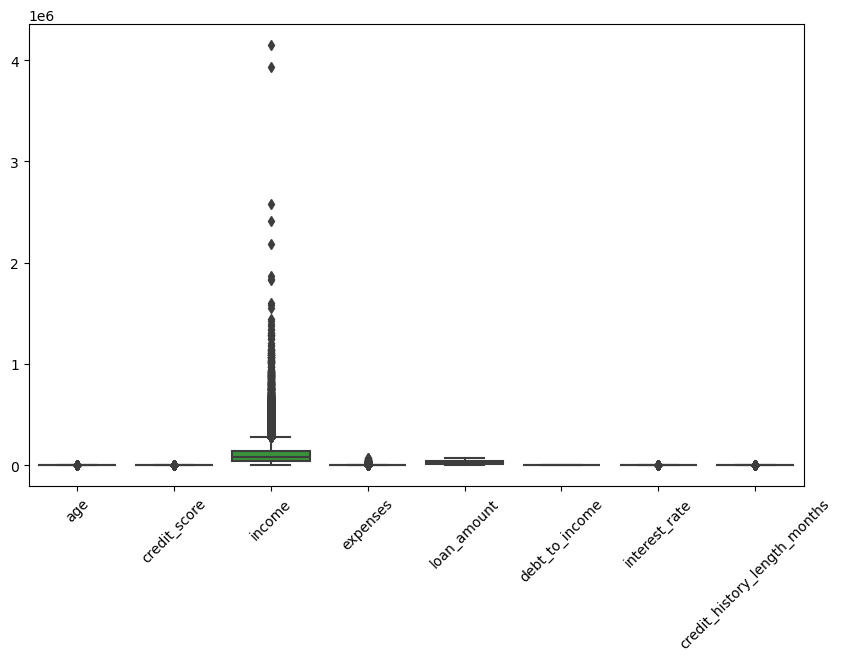

In [29]:
plt.figure(figsize=(10,6))
sns.boxplot(df[cols_for_outliers])
plt.xticks(rotation=45);

In [30]:
def cap_outliers(df, column):
    Q1=df[column].quantile(0.25)
    Q3=df[column].quantile(0.75)

    IQR=Q3-Q1

    lower_bound=Q1-1.5*IQR
    upper_bound=Q3+1.5*IQR

    df[column]=np.where(df[column]>upper_bound,upper_bound,df[column])
    df[column]=np.where(df[column]<lower_bound,lower_bound,df[column])

    return df

In [31]:
for col in cols_for_outliers:
    df=cap_outliers(df, col)

In [32]:
df.shape

(49933, 22)

# 2. Exploratory Data Analysis (EDA)

### 2.1 Summary statistics of loan amount, income, credit score

In [33]:
df[['loan_amount', 'income', 'credit_score']].describe()

,loan_amount,income,credit_score
count,49933.000000,49933.000000,49933.000000
mean,31050.164100,99902.272901,697.863137
std,22058.479952,75107.678909,82.080522
min,501.000000,0.000000,471.000000
25%,13651.000000,44559.850000,642.000000
50%,24501.000000,78901.340000,700.000000
75%,44237.000000,136642.160000,756.000000
max,75000.000000,274765.625000,850.000000


The dataset shows a well-distributed range of values across key financial features following initial cleaning. Loan amounts range from 501 to 75,000 dollars, with a mean of approximately 31,051 and a median of 24,501, suggesting a slightly right-skewed distribution. Income exhibits a wide spread, ranging from 0 to over 274,000 dollars annually. The mean income is around 99,998 dollars, while the median is lower at 78,901, indicating that a portion of high-income borrowers still contributes to positive skew, although extreme outliers have been reduced. The presence of zero-income values likely represents unemployed individuals. Credit scores span from 471 to 850, with a median of 700 and a mean of 698, reflecting a near-normal distribution centered in the “fair to good” credit risk range. These statistics confirm that the cleaned dataset retains realistic borrower diversity and preserves useful variation for predictive modeling.

### 2.2 Distribution plots:

Income, loan term, credit score, interest rate

C:\Users\laman\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


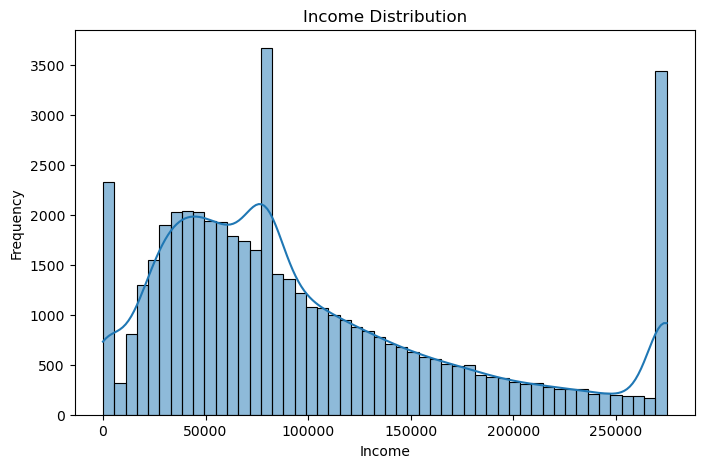

In [34]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='income', bins=50, kde=True)
plt.title('Income Distribution')
plt.xlabel('Income')
plt.ylabel('Frequency')
plt.show()

The income distribution is right skewed, with the majority of borrowers earning between 20,000 and 120,000 dollars annually. The histogram shows a clear concentration of values around 85,000 dollars, indicating that a large portion of applicants fall within the middle income range. The frequency of borrowers decreases gradually as income increases, forming a long right tail. This pattern suggests the presence of higher earning individuals, though extreme outliers have been reduced or capped. The overall distribution presents a plausible range of income values suitable for credit risk analysis and predictive modeling.

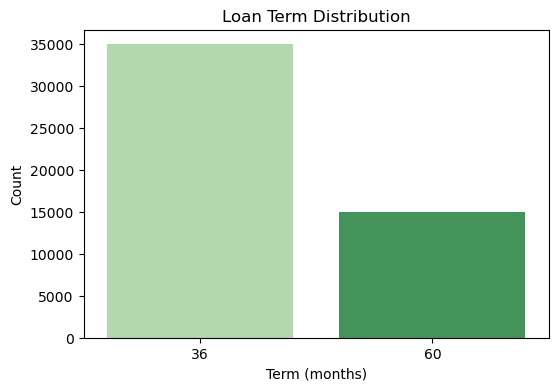

In [35]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='term', palette='Greens')
plt.title('Loan Term Distribution')
plt.xlabel('Term (months)')
plt.ylabel('Count')
plt.show()

The loan term distribution includes two available repayment durations, 36 months and 60 months. A larger proportion of borrowers selected the 36 month term, while a smaller group chose the 60 month option. This reflects common lending practices, where shorter-term personal loans are more frequently offered or preferred due to lower total interest costs and quicker repayment periods. The imbalance between the two term lengths also aligns with the simulation design, in which 36 month terms were assigned with higher probability. The resulting distribution supports meaningful analysis of borrower behavior and repayment risk across different loan durations.

C:\Users\laman\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


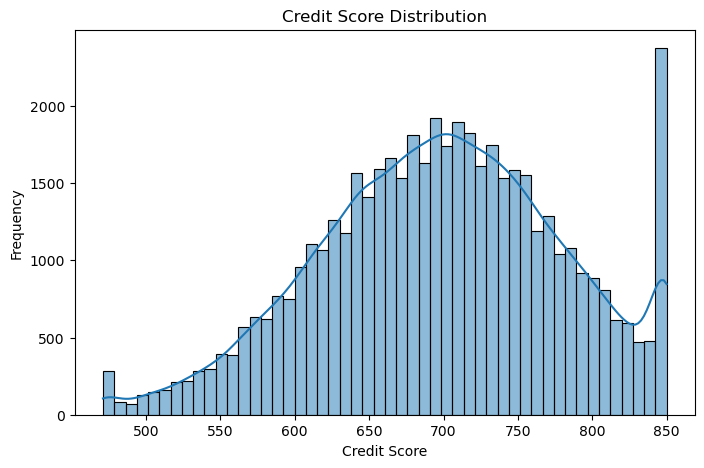

In [36]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='credit_score', bins=50, kde=True)
plt.title('Credit Score Distribution')
plt.xlabel('Credit Score')
plt.ylabel('Frequency')
plt.show()

The credit score distribution is centered around a score of 700, with most values falling between 600 and 800. The shape of the distribution is slightly left skewed, as the left tail toward lower scores extends more gradually while the right side declines more steeply. A noticeable spike is present at the maximum score of 850, likely caused by score capping during data generation. Scores below 600 appear less frequently, indicating a smaller representation of high-risk borrowers. Overall, the distribution reflects a realistic range of credit profiles and supports effective segmentation in credit risk modeling.

C:\Users\laman\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


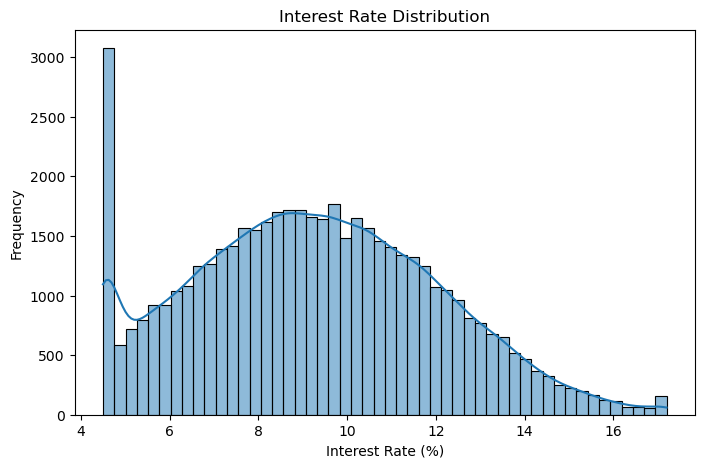

In [37]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='interest_rate', bins=50, kde=True)
plt.title('Interest Rate Distribution')
plt.xlabel('Interest Rate (%)')
plt.ylabel('Frequency')
plt.show()

The interest rate distribution shows a right skewed pattern, with most rates concentrated between 6 percent and 12 percent. A sharp spike is visible at the lower bound of 4.5 percent, which likely reflects a floor or cap applied during interest rate assignment. The long right tail suggests that a smaller group of borrowers face higher interest rates, possibly due to weaker credit profiles or risk-based pricing mechanisms. This distribution captures realistic lending behavior and supports further analysis of how interest rates relate to borrower risk.

### 2.3 Analyze relationships:
Default rate by: Credit score bucket, Loan purpose, Term or DTI ratio

In [38]:
bins = [300, 600, 700, 800, 851]
labels = ['<600 (Poor)', '600–700 (Fair)', '700–800 (Good)', '800+ (Excellent)']
df['credit_score_bucket'] = pd.cut(df['credit_score'], bins=bins, labels=labels, right=False)

C:\Users\laman\AppData\Local\Temp\ipykernel_22428\2113821412.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_score_bucket = df.groupby('credit_score_bucket')['default'].mean().reset_index()
C:\Users\laman\anaconda3\Lib\site-packages\plotly\express\_core.py:1958: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = df.groupby(required_grouper, sort=False)  # skip one_group groupers


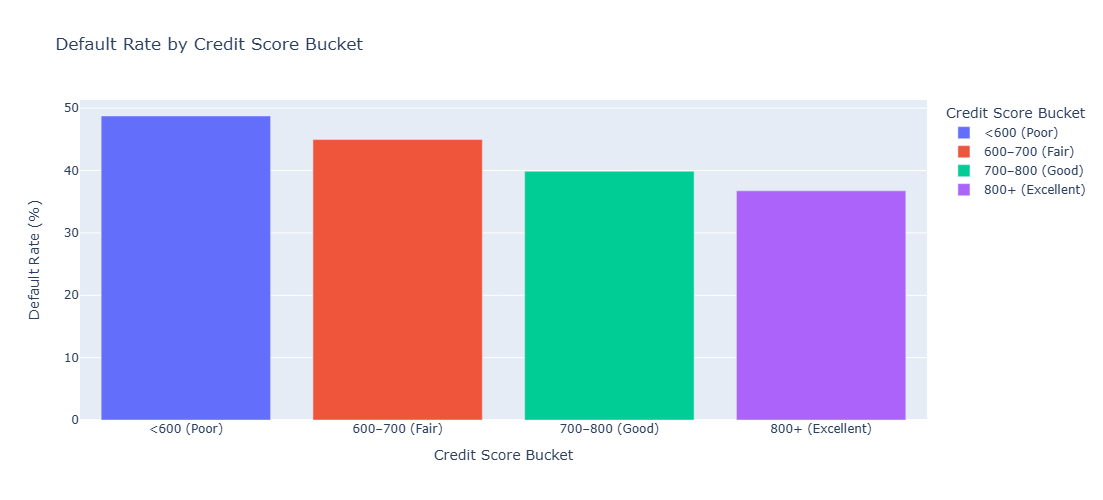

In [39]:
df_score_bucket = df.groupby('credit_score_bucket')['default'].mean().reset_index()
df_score_bucket['default_rate_percent'] = df_score_bucket['default'] * 100

score_plot = px.bar(
    df_score_bucket,
    x='credit_score_bucket',
    y='default_rate_percent',
    title='Default Rate by Credit Score Bucket',
    labels={'default_rate_percent': 'Default Rate (%)', 'credit_score_bucket': 'Credit Score Bucket'},
    color='credit_score_bucket',
    height=500
)
score_plot.show()

In [40]:
df_score_bucket

,credit_score_bucket,default,default_rate_percent
0,<600 (Poor),0.487427,48.742714
1,600–700 (Fair),0.449659,44.965911
2,700–800 (Good),0.398732,39.873219
3,800+ (Excellent),0.367461,36.746072


The chart shows a clear inverse relationship between credit score and default rate. Borrowers with credit scores below 600 have the highest default rate, approaching 49 percent. As credit scores improve, the default rate declines steadily. The group with scores between 600 and 700 has a default rate of approximately 45 percent, while those in the 700 to 800 range default at a rate near 40 percent. Borrowers with scores above 800 exhibit the lowest default rate, around 37 percent. This pattern aligns with expectations, as higher credit scores generally reflect stronger creditworthiness and lower risk. The results confirm credit score as a meaningful predictor of default behavior.

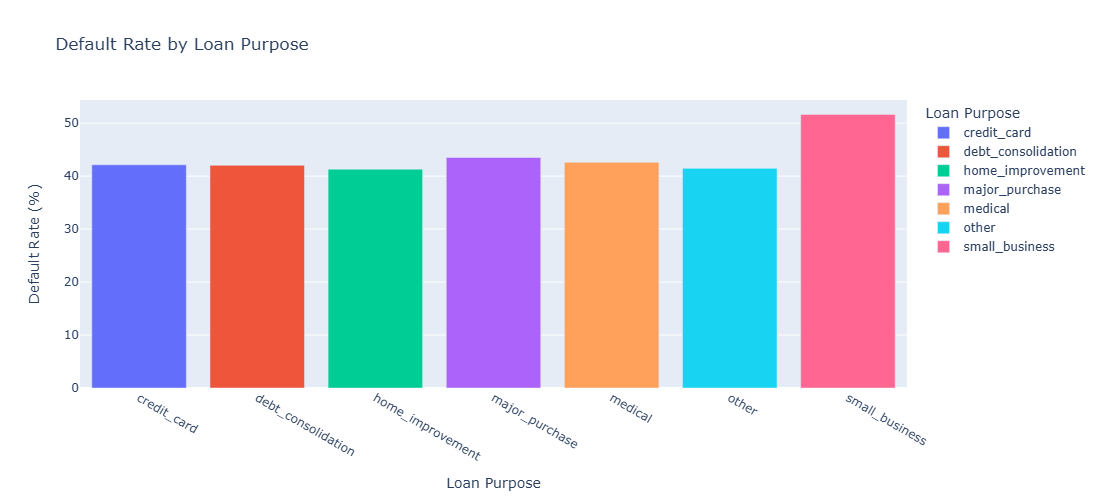

In [41]:
df_purpose=df.groupby('loan_purpose')['default'].mean().reset_index()
df_purpose['default_rate_percent']=df_purpose['default']*100

purpose_plot = px.bar(
    df_purpose,
    x='loan_purpose',
    y='default_rate_percent',
    title='Default Rate by Loan Purpose',
    labels={'default_rate_percent': 'Default Rate (%)', 'loan_purpose': 'Loan Purpose'},
    color='loan_purpose',
    height=500
)
purpose_plot.show()

In [42]:
df_purpose

,loan_purpose,default,default_rate_percent
0,credit_card,0.421328,42.132797
1,debt_consolidation,0.420438,42.043757
2,home_improvement,0.412995,41.299537
3,major_purchase,0.435166,43.516576
4,medical,0.425987,42.598684
5,other,0.414663,41.466346
6,small_business,0.516510,51.651040


The chart displays variation in default rates across different loan purposes. Borrowers who used loans for small business purposes exhibit the highest default rate, exceeding 50 percent. This suggests a higher risk associated with business-related lending, possibly due to revenue uncertainty or lack of collateral. Other categories such as credit card refinancing, debt consolidation, medical expenses, and home improvement show similar default rates, all clustered between 41 and 43 percent. Loans for major purchases have a slightly higher default rate than most consumer-focused categories. These findings highlight the importance of loan purpose in assessing credit risk, with small business loans standing out as significantly riskier than other categories.

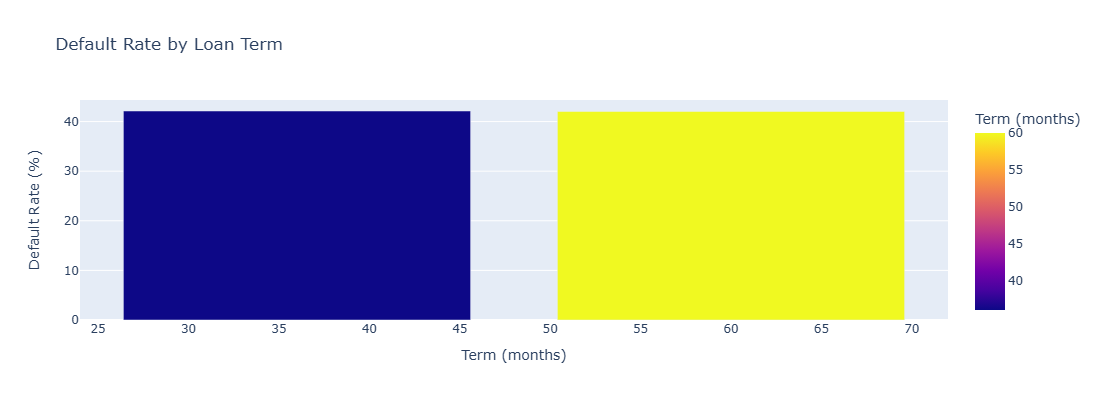

In [43]:
df_term=df.groupby('term')['default'].mean().reset_index()
df_term['default_rate_percent']=df_purpose['default']*100

term_plot = px.bar(
    df_term,
    x='term',
    y='default_rate_percent',
    title='Default Rate by Loan Term',
    labels={'default_rate_percent': 'Default Rate (%)', 'term': 'Term (months)'},
    color='term',
    height=400
)
term_plot.show()

In [44]:
df_term

,term,default,default_rate_percent
0,36,0.426536,42.132797
1,60,0.421379,42.043757


The chart compares default rates across the two available loan terms: 36 months and 60 months. Both terms show nearly identical default rates, slightly above 42 percent. This suggests that loan duration alone may not be a strong differentiator of credit risk in this dataset. Despite the longer repayment period and potentially higher total interest cost associated with 60-month loans, default behavior appears consistent across both groups. These findings imply that term length may have limited predictive power when isolated from other borrower characteristics such as credit score, income, or loan purpose.

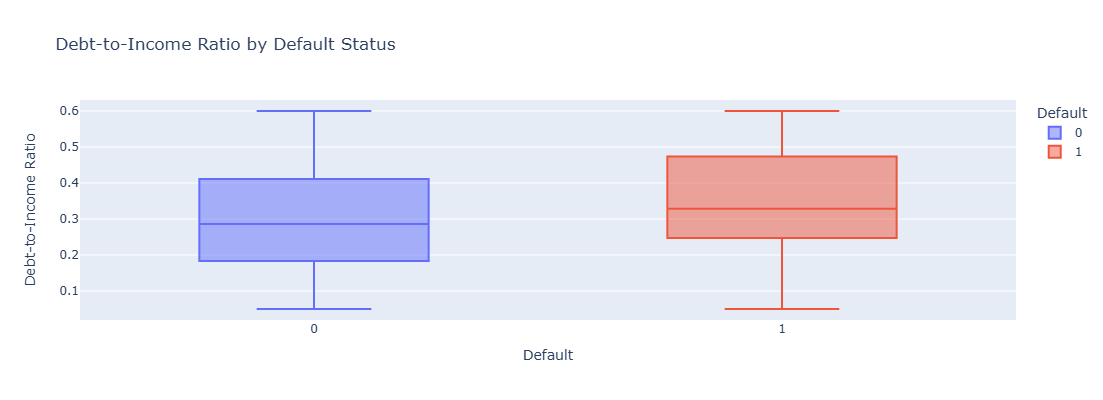

In [45]:
dti_box = px.box(
    df,
    x='default',
    y='debt_to_income',
    title='Debt-to-Income Ratio by Default Status',
    labels={'default': 'Default', 'debt_to_income': 'Debt-to-Income Ratio'},
    color='default',
    height=400
)
dti_box.show()

The boxplot compares the distribution of debt-to-income (DTI) ratios between borrowers who repaid their loans and those who defaulted. Borrowers who defaulted generally have higher DTI ratios, with a median closer to 0.33 compared to approximately 0.28 for those who did not default. The interquartile range is also wider among defaulters, indicating greater variability in financial stress levels. Both groups have similar maximum values, capped around 0.6, but defaulters tend to have a higher concentration of DTI values in the upper range. This suggests that borrowers with heavier debt burdens relative to income are more likely to default, making DTI an important feature for credit risk assessment.

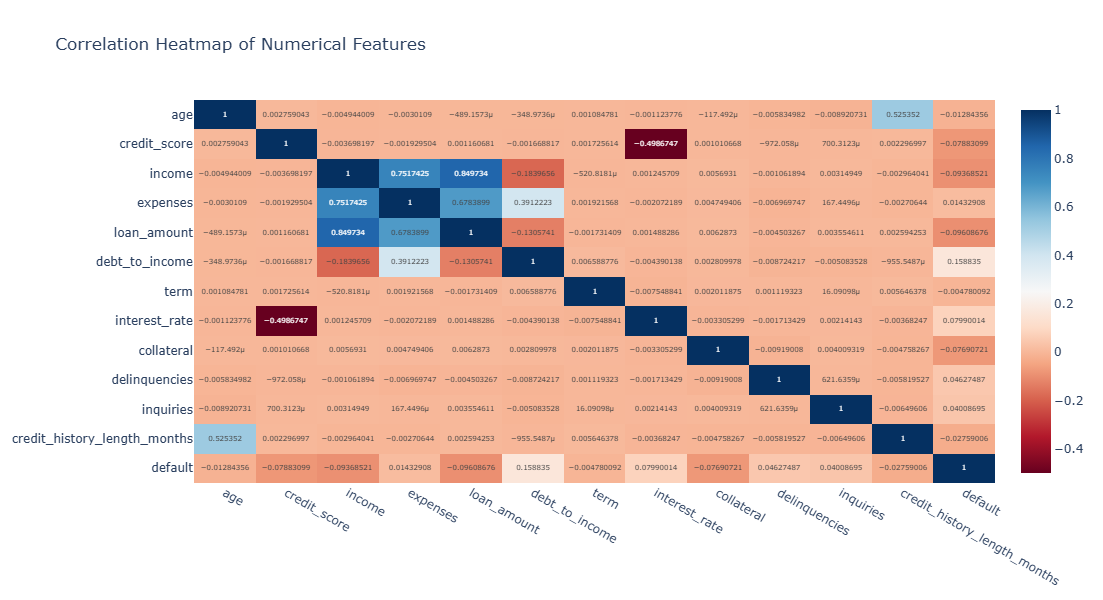

In [46]:
corr_matrix = df.select_dtypes(include=np.number).corr()

fig_corr = px.imshow(corr_matrix,
                     text_auto=True,
                     aspect="auto",
                     color_continuous_scale='RdBu',
                     title='Correlation Heatmap of Numerical Features')
fig_corr.update_layout(height=600, width=1000)
fig_corr.show()

The heatmap illustrates the pairwise correlations among key numerical features in the dataset. Most correlations are relatively weak, suggesting low multicollinearity across predictors. A few relationships stand out: income and loan amount show a strong positive correlation (r ≈ 0.85), indicating that higher-income borrowers tend to request larger loans. Expenses and income are also highly correlated (r ≈ 0.75), reflecting natural financial behavior. Credit score is negatively correlated with interest rate (r ≈ -0.50), consistent with risk-based pricing practices. Default shows modest positive correlation with debt-to-income ratio (r ≈ 0.16) and slight negative correlation with credit score and loan amount, suggesting that borrowers with higher risk indicators are somewhat more likely to default. Overall, the heatmap confirms that several financial and behavioral variables contribute meaningfully to credit risk.

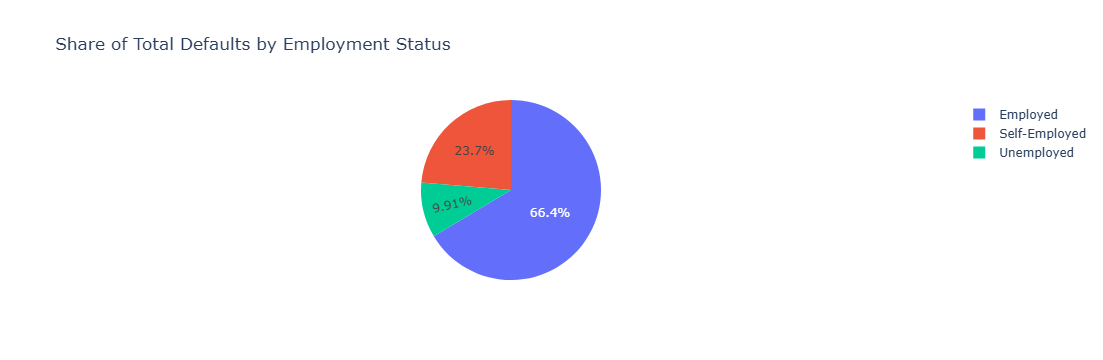

In [47]:
cat_col = 'employment_status'
default_counts = df[df['default'] == 1][cat_col].value_counts().reset_index()
default_counts.columns = [cat_col, 'count']

pie_chart = px.pie(
    default_counts,
    names=cat_col,
    values='count',
    title=f'Share of Total Defaults by {cat_col.replace("_", " ").title()}'
)
pie_chart.show()

The pie chart shows the distribution of total defaults across employment categories. Employed individuals account for the majority of defaults, representing approximately 66.4 percent of all default cases. Self-employed borrowers contribute 23.7 percent, while unemployed applicants make up 9.9 percent of total defaults. These proportions likely reflect the overall composition of the applicant pool, where employed individuals are the dominant group. However, the chart does not account for default rates within each category. To gain a more accurate understanding of credit risk by employment status, this visualization should be complemented by default rate analysis, which considers the number of defaults relative to the size of each employment group.

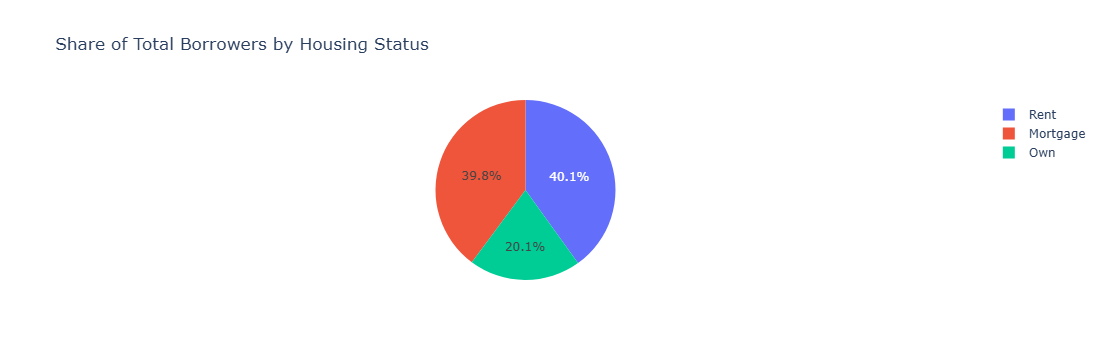

In [48]:
cat_col = 'housing_status'
total_counts = df[cat_col].value_counts().reset_index()
total_counts.columns = [cat_col, 'count']

pie_total = px.pie(
    total_counts,
    names=cat_col,
    values='count',
    title=f'Share of Total Borrowers by {cat_col.replace("_", " ").title()}'
)
pie_total.show()

The pie chart displays the distribution of borrowers by housing status. Renters represent the largest group, accounting for 40.1 percent of the dataset. Borrowers with a mortgage closely follow at 39.8 percent, while homeowners without a mortgage make up the remaining 20.1 percent. This distribution reflects a diverse range of housing circumstances among applicants, with nearly equal representation between renters and mortgage holders. Understanding housing status is relevant for credit risk analysis, as it can influence financial stability, disposable income, and default behavior. 

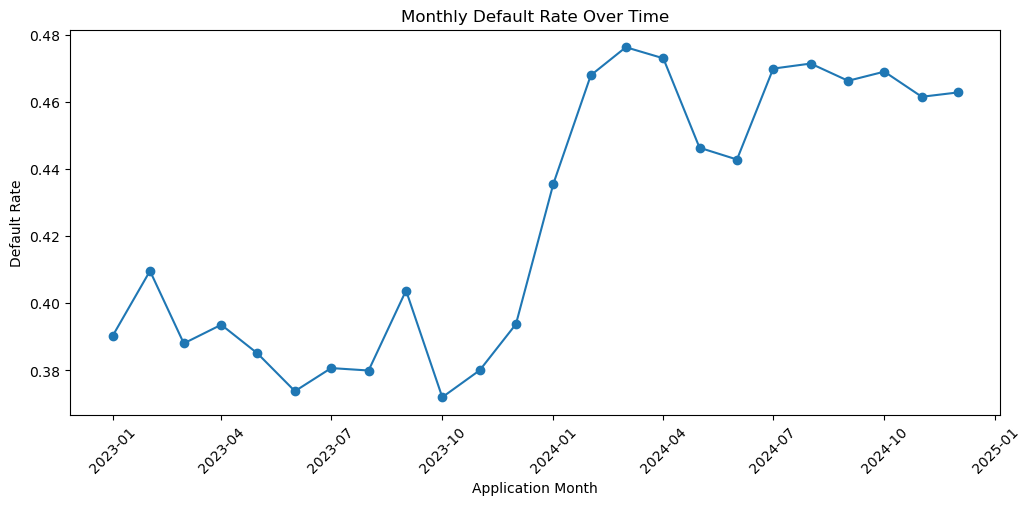

In [49]:
monthly_defaults = (
    df.groupby(df['application_date'].dt.to_period('M'))['default']
    .mean()
    .reset_index()
)
monthly_defaults['application_date'] = monthly_defaults['application_date'].dt.to_timestamp()

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_defaults['application_date'],
    monthly_defaults['default'],
    marker='o',
    linestyle='-'
)
plt.title('Monthly Default Rate Over Time')
plt.xlabel('Application Month')
plt.ylabel('Default Rate')
plt.xticks(rotation=45)
plt.show()

The line chart illustrates how the default rate varied over time based on application month. From January 2023 through late 2023, default rates remained relatively stable, fluctuating mildly between 37% and 41%. However, starting around December 2023 and into early 2024, there is a noticeable and sustained increase in default rates, reaching a peak of nearly 48% by March–April 2024. This upward shift corresponds with the onset of the "Stressed" economic cycle in 2024, indicating that broader macroeconomic conditions likely influenced borrower risk profiles.

Following the peak, the default rate remains elevated throughout the rest of 2024, maintaining a plateau near 46–47%. This suggests that economic stress conditions had a lasting impact on credit performance.

# 3. Feature Engineering

### 3.1 fico_bucket

In [50]:
bins = [300, 600, 700, 800, 851]
labels = ['<600 (Poor)', '600–700 (Fair)', '700–800 (Good)', '800+ (Excellent)']
df['credit_score_bucket'] = pd.cut(df['credit_score'], bins=bins, labels=labels, right=False)

### 3.2 loan_to_income_ratio

In [51]:
df['loan_to_income_ratio'] = df['loan_amount'] / df['income']

### 3.3 installment_to_income

In [52]:
df['installment_to_income'] = (df['loan_amount'] / df['term']) / (df['income'] / 12)

### 3.4 has_recent_delinquency

In [53]:
df['has_recent_delinquency'] = (df['delinquencies'] > 0).astype(int)

### 3.5 credit_history_length

In [54]:
df['credit_history_length'] = df['credit_history_length_months'] / 12

### 3.6 high_risk_purpose

In [55]:
high_risk_categories = ['small_business', 'other', 'medical', 'major_purchase']
df['high_risk_purpose'] = df['loan_purpose'].isin(high_risk_categories).astype(int)

In [56]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df = df.fillna(df.median(numeric_only=True))

# 4. Data Preprocessing

### 4.1 Encoding Categorical Values

In [57]:
df.head()

,age,gender,marital_status,employment_status,housing_status,credit_score,income,expenses,loan_amount,debt_to_income,term,interest_rate,collateral,loan_purpose,loan_title,delinquencies,inquiries,credit_history_length_months,application_date,economic_cycle,state,default,credit_score_bucket,loan_to_income_ratio,installment_to_income,has_recent_delinquency,credit_history_length,high_risk_purpose
0,42.0,Female,Married,Self-Employed,Mortgage,756.0,150844.620,6813.44,74798.0,0.5744,36,14.29,0,credit_card,Credit_card.,0,2,4.0,2024-10-16,Stressed,NY,0,700–800 (Good),0.495861,0.165287,0,0.333333,0
1,37.0,Female,Married,Unemployed,Mortgage,649.0,78901.340,0.00,3499.0,0.0580,36,8.17,1,debt_consolidation,debt_consolidation loan for memory,1,2,171.0,2023-04-25,Stable,IL,1,600–700 (Fair),0.044347,0.014782,1,14.250000,0
2,43.0,Female,Married,Employed,Rent,594.0,54073.890,754.31,20101.0,0.1911,36,8.53,0,debt_consolidation,debt_consolidation loan for support,0,3,170.0,2023-01-26,Stable,FL,1,<600 (Poor),0.371732,0.123911,0,14.166667,0
3,33.0,Male,Married,Employed,Own,619.0,274765.625,6830.27,75000.0,0.4905,60,6.86,0,debt_consolidation,Debt_consolidation.,0,0,106.0,2023-10-09,Stable,CA,1,600–700 (Fair),0.272960,0.054592,0,8.833333,0
4,51.0,Male,Single,Employed,Mortgage,579.0,53791.370,1166.32,28997.0,0.2614,60,9.69,0,debt_consolidation,debt_consolidation loan for expect,0,1,243.0,2023-09-08,Stable,IL,0,<600 (Poor),0.539064,0.107813,0,20.250000,0


In [58]:
df['gender'] = df['gender'].replace({'Male': 0, 'Female': 1, 'Other': 2})

In [59]:
df['economic_cycle'] = df['economic_cycle'].replace({'Stable': 0, 'Stressed': 1})

In [60]:
df.marital_status.value_counts()

marital_status
Married     24883
Single      22597
Divorced     2453
Name: count, dtype: int64

In [61]:
df = pd.get_dummies(df, columns=['marital_status'], prefix='', prefix_sep='', dtype='int')

In [62]:
df.employment_status.value_counts()

employment_status
Employed         34979
Self-Employed    12552
Unemployed        2402
Name: count, dtype: int64

In [63]:
df = pd.get_dummies(df, columns=['employment_status'], prefix='', prefix_sep='', dtype='int')

In [64]:
df.housing_status.value_counts()

housing_status
Rent        20014
Mortgage    19888
Own         10031
Name: count, dtype: int64

In [65]:
df = pd.get_dummies(df, columns=['housing_status'], prefix='Housing', prefix_sep='_', dtype='int')

In [66]:
df.loan_purpose.value_counts()

loan_purpose
debt_consolidation    22762
credit_card            9940
other                  4992
home_improvement       4971
small_business         2453
medical                2432
major_purchase         2383
Name: count, dtype: int64

In [67]:
df = pd.get_dummies(df, columns=['loan_purpose'], prefix='loan', prefix_sep='_', dtype='int')

In [68]:
df.drop('loan_title', axis=1, inplace=True)

In [69]:
df.credit_score_bucket.value_counts()

credit_score_bucket
700–800 (Good)      19088
600–700 (Fair)      18921
<600 (Poor)          6005
800+ (Excellent)     5919
Name: count, dtype: int64

In [70]:
df.drop('credit_score_bucket', axis=1, inplace=True)

In [71]:
df.state.value_counts()

state
TX    10096
NY    10027
FL     9988
CA     9930
IL     9892
Name: count, dtype: int64

In [72]:
df.drop('state', axis=1, inplace=True)

In [73]:
df['term_60_month'] = (df['term'] == 60).astype(int)

In [74]:
df.drop(columns=['credit_history_length_months'], inplace=True)

In [75]:
df.drop('application_date', axis=1, inplace=True)

In [76]:
df.drop('term', axis=1, inplace=True)

# 5. Model Building

### 5.1 Split data into training (80%) and testing (20%) using stratified sampling

In [77]:
from sklearn.model_selection import train_test_split

In [448]:
df.columns

Index(['age', 'gender', 'credit_score', 'income', 'expenses', 'loan_amount',
       'debt_to_income', 'interest_rate', 'collateral', 'delinquencies',
       'inquiries', 'economic_cycle', 'default', 'loan_to_income_ratio',
       'installment_to_income', 'has_recent_delinquency',
       'credit_history_length', 'high_risk_purpose', 'Divorced', 'Married',
       'Single', 'Employed', 'Self-Employed', 'Unemployed', 'Housing_Mortgage',
       'Housing_Own', 'Housing_Rent', 'loan_credit_card',
       'loan_debt_consolidation', 'loan_home_improvement',
       'loan_major_purchase', 'loan_medical', 'loan_other',
       'loan_small_business', 'term_60_month', 'PD', 'Risk_Band',
       'Expected_Loss', 'PD_decile'],
      dtype='object')

In [450]:
X=df.drop(columns=['default'])
y=df['default']

In [185]:
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

### 4.2 Normalize/scale numerical features (if needed)

In [186]:
from sklearn.preprocessing import StandardScaler

In [187]:
scaler = StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [208]:
X_train = pd.DataFrame(X_train, columns=X.columns)
X_test = pd.DataFrame(X_test, columns=X.columns)

### 5.2 Logistic Regression (baseline, interpretable)

In [82]:
from sklearn.linear_model import LogisticRegression

In [209]:
log_reg_model = LogisticRegression(max_iter=1000, solver='liblinear', random_state=42)

In [210]:
log_reg_model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')

### 5.3 Tree-based model: Random Forest, XGBoost, or LightGBM

In [211]:
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from xgboost import XGBClassifier
import lightgbm as lgb
from lightgbm import LGBMClassifier

In [212]:
rf_model = RandomForestClassifier(random_state=42)

In [213]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [214]:
xgb_model=XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective='binary:logistic',
    eval_metric='logloss',
    use_label_encoder=False,
    random_state=42
)

In [215]:
xgb_model.fit(X_train, y_train)

C:\Users\laman\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning:

[19:20:01] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0015a694724fa8361-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.




XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, random_state=42, ...)

In [216]:
lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=-1,
    random_state=42
)

In [217]:
lgbm_model.fit(X_train, y_train)

[LightGBM] [Info] Number of positive: 16977, number of negative: 22969
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004220 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2417
[LightGBM] [Info] Number of data points in the train set: 39946, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.424999 -> initscore=-0.302286
[LightGBM] [Info] Start training from score -0.302286


LGBMClassifier(random_state=42)

# 6. Evaluation Metrics

In [218]:
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report, precision_recall_curve, f1_score, precision_score, recall_score

### 6.1 AUC-ROC Score & Curve

In [219]:
# Logistic Regression

In [220]:
y_proba = log_reg_model.predict_proba(X_test)[:, 1]

In [221]:
auc_score = roc_auc_score(y_test, y_proba)
print("AUC-ROC Score for Logistic regression:", round(auc_score, 4))

AUC-ROC Score for Logistic regression: 0.6658


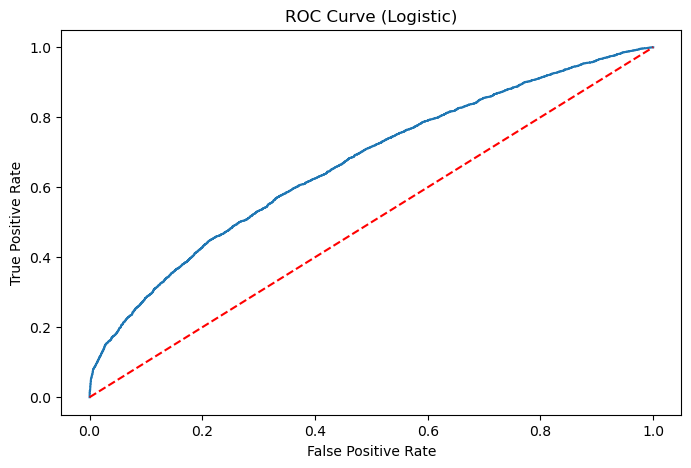

In [222]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.2f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='red')
plt.title("ROC Curve (Logistic)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

In [223]:
# RF

In [224]:
y_proba = rf_model.predict_proba(X_test)[:, 1]

In [225]:
auc_score = roc_auc_score(y_test, y_proba)
print("AUC-ROC Score for RF:", round(auc_score, 4))

AUC-ROC Score for RF: 0.6476


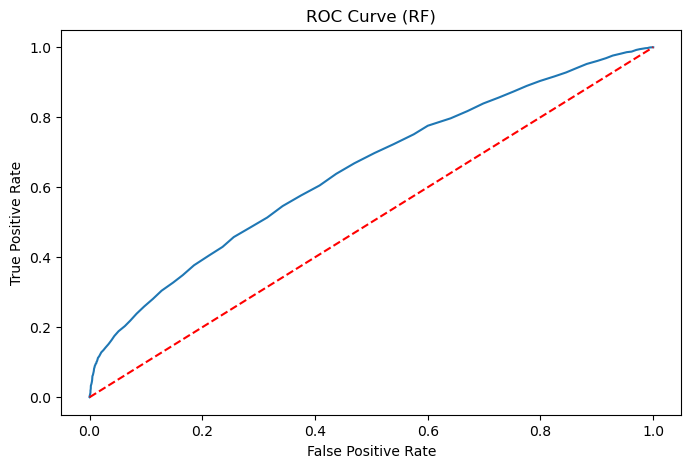

In [226]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.2f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='red')
plt.title("ROC Curve (RF)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

In [227]:
# XGB

In [228]:
y_proba = xgb_model.predict_proba(X_test)[:, 1]

In [229]:
auc_score = roc_auc_score(y_test, y_proba)
print("AUC-ROC Score for XGB:", round(auc_score, 4))

AUC-ROC Score for XGB: 0.6573


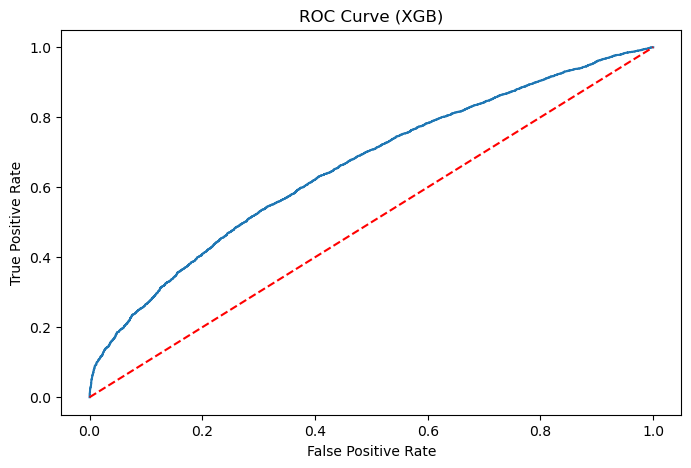

In [230]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.2f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='red')
plt.title("ROC Curve (XGB)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

In [231]:
# LGBM

In [232]:
y_proba = lgbm_model.predict_proba(X_test)[:, 1]

In [233]:
auc_score = roc_auc_score(y_test, y_proba)
print("AUC-ROC Score for LGBM:", round(auc_score, 4))

AUC-ROC Score for LGBM: 0.6547


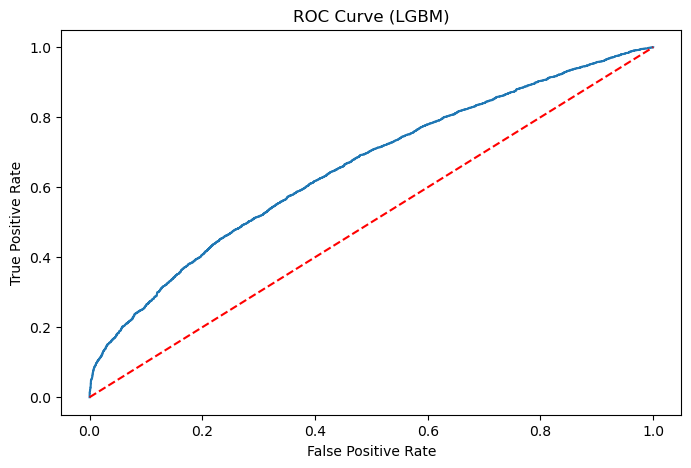

In [234]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.2f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='red')
plt.title("ROC Curve (LGBM)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

### 6.2 Confusion Matrix + Precision, Recall, F1

In [235]:
models = {
    'Logistic Regression': log_reg_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgbm_model
}

In [236]:
for name, model in models.items():
    y_pred=model.predict(X_test)
    
    print(f"=== {name} ===")
    print("F1 Score:\n", f1_score(y_test, y_pred)),
    print("\nPrecision:\n", precision_score(y_test, y_pred)),
    print("\nRecall:\n", recall_score(y_test, y_pred)),
    print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))
    print("=" * 40 + "\n")

=== Logistic Regression ===
F1 Score:
 0.465380589202931

Precision:
 0.6369218174375767

Recall:
 0.36663524976437323

Confusion Matrix:
 [[4856  887]
 [2688 1556]]

Classification Report:
               precision    recall  f1-score   support

           0     0.6437    0.8456    0.7309      5743
           1     0.6369    0.3666    0.4654      4244

    accuracy                         0.6420      9987
   macro avg     0.6403    0.6061    0.5982      9987
weighted avg     0.6408    0.6420    0.6181      9987


=== Random Forest ===
F1 Score:
 0.4435786003296868

Precision:
 0.6093042404281598

Recall:
 0.34872761545711595

Confusion Matrix:
 [[4794  949]
 [2764 1480]]

Classification Report:
               precision    recall  f1-score   support

           0     0.6343    0.8348    0.7208      5743
           1     0.6093    0.3487    0.4436      4244

    accuracy                         0.6282      9987
   macro avg     0.6218    0.5917    0.5822      9987
weighted avg     0.6237

### 6.3 Precision-Recall Curve

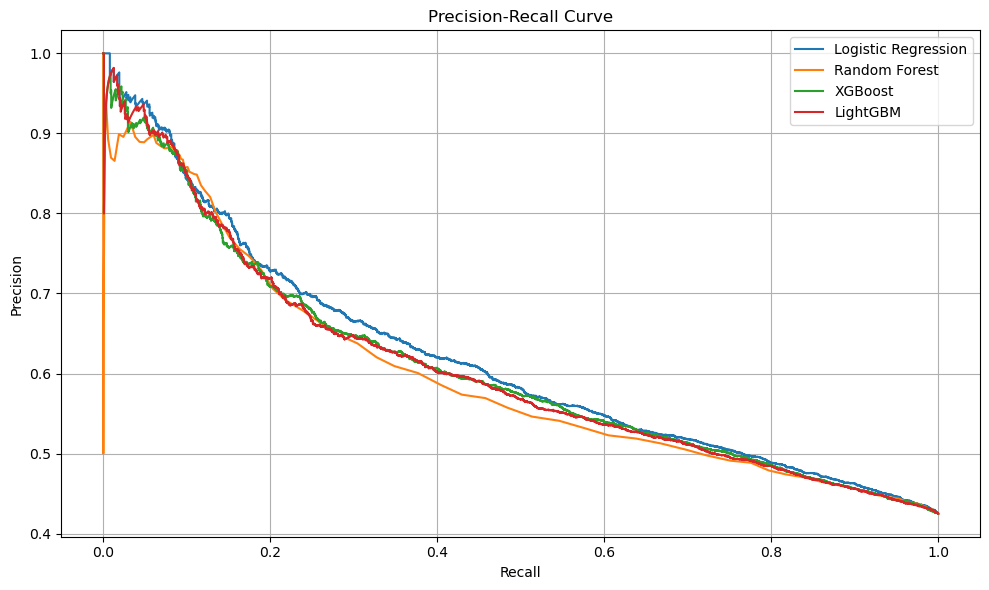

In [237]:
plt.figure(figsize=(10, 6))

for name, model in models.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    plt.plot(recall, precision, label=name)

plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 6.4 KS Statistic (Kolmogorov–Smirnov)

In [238]:
for name, model in models.items():
    y_proba=model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    ks_statistic = np.max(tpr - fpr)
    print(f"{name} - KS Statistic: {ks_statistic:.4f}")

Logistic Regression - KS Statistic: 0.2386
Random Forest - KS Statistic: 0.2037
XGBoost - KS Statistic: 0.2300
LightGBM - KS Statistic: 0.2215


### 6.5 Threshold Tuning

In [446]:
df.default.value_counts()

default
0    28712
1    21221
Name: count, dtype: int64

In [239]:
thresholds = np.arange(0.1, 0.91, 0.1)

for name, model in models.items():
    print(f"\n=== {name} ===")
    y_proba = model.predict_proba(X_test)[:, 1]
    
    for thresh in thresholds:
        y_pred_thresh = (y_proba >= thresh).astype(int)
        print(f"\nThreshold: {thresh:.1f}")
        print(classification_report(y_test, y_pred_thresh, digits=4))


=== Logistic Regression ===

Threshold: 0.1
              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000      5743
           1     0.4250    1.0000    0.5964      4244

    accuracy                         0.4250      9987
   macro avg     0.2125    0.5000    0.2982      9987
weighted avg     0.1806    0.4250    0.2535      9987


Threshold: 0.2
              precision    recall  f1-score   support

           0     0.8447    0.0303    0.0585      5743
           1     0.4306    0.9925    0.6006      4244

    accuracy                         0.4392      9987
   macro avg     0.6376    0.5114    0.3296      9987
weighted avg     0.6687    0.4392    0.2889      9987


Threshold: 0.3
              precision    recall  f1-score   support

           0     0.7433    0.2572    0.3821      5743
           1     0.4667    0.8798    0.6099      4244

    accuracy                         0.5218      9987
   macro avg     0.6050    0.5685    0.4960      99

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning:

Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning:

Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning:

Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



              precision    recall  f1-score   support

           0     0.6437    0.8456    0.7309      5743
           1     0.6369    0.3666    0.4654      4244

    accuracy                         0.6420      9987
   macro avg     0.6403    0.6061    0.5982      9987
weighted avg     0.6408    0.6420    0.6181      9987


Threshold: 0.6
              precision    recall  f1-score   support

           0     0.6092    0.9617    0.7459      5743
           1     0.7611    0.1652    0.2714      4244

    accuracy                         0.6232      9987
   macro avg     0.6852    0.5634    0.5087      9987
weighted avg     0.6738    0.6232    0.5443      9987


Threshold: 0.7
              precision    recall  f1-score   support

           0     0.5968    0.9873    0.7439      5743
           1     0.8501    0.0975    0.1750      4244

    accuracy                         0.6092      9987
   macro avg     0.7235    0.5424    0.4595      9987
weighted avg     0.7045    0.6092    0.502

# 7. Model Explainability

In [240]:
# coef_ from logistic regression

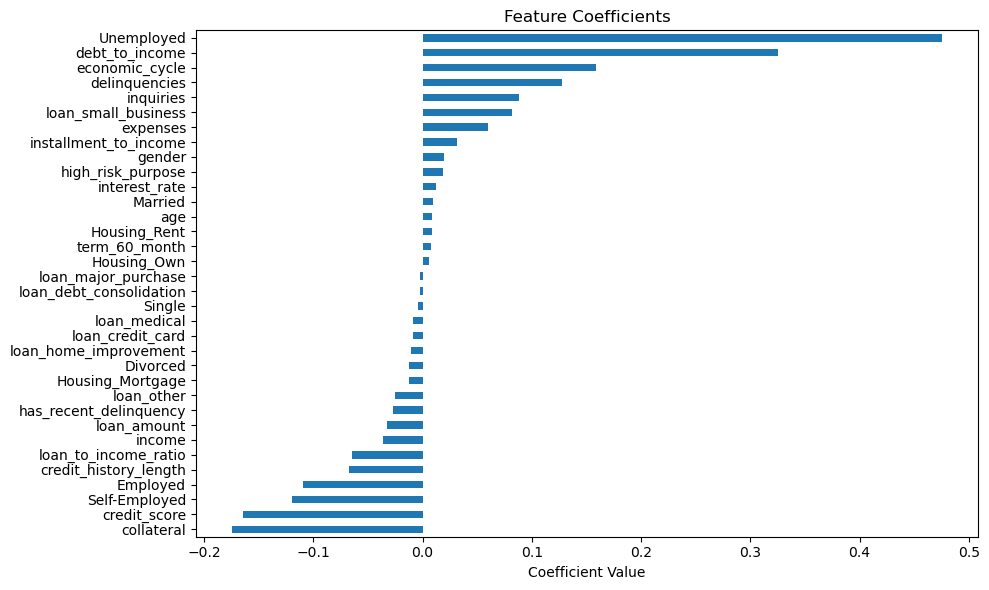

In [241]:
linear_coef=pd.Series(log_reg_model.coef_[0], index=X.columns).sort_values()
plt.figure(figsize=(10, 6))
linear_coef.plot(kind='barh')
plt.title('Feature Coefficients')
plt.xlabel('Coefficient Value')
plt.tight_layout()
plt.show()

The plot above presents the feature coefficients for the logistic regression model. Features such as Unemployed, debt_to_income, and economic_cycle have the highest positive coefficients, indicating a strong association with increased default risk. Conversely, features like collateral, credit_score, and employment status (especially Self-Employed) exhibit negative coefficients, suggesting they contribute to a lower likelihood of default. These results reflect expected credit risk patterns and support the model's interpretability.

In [242]:
# Feature importance (tree models)

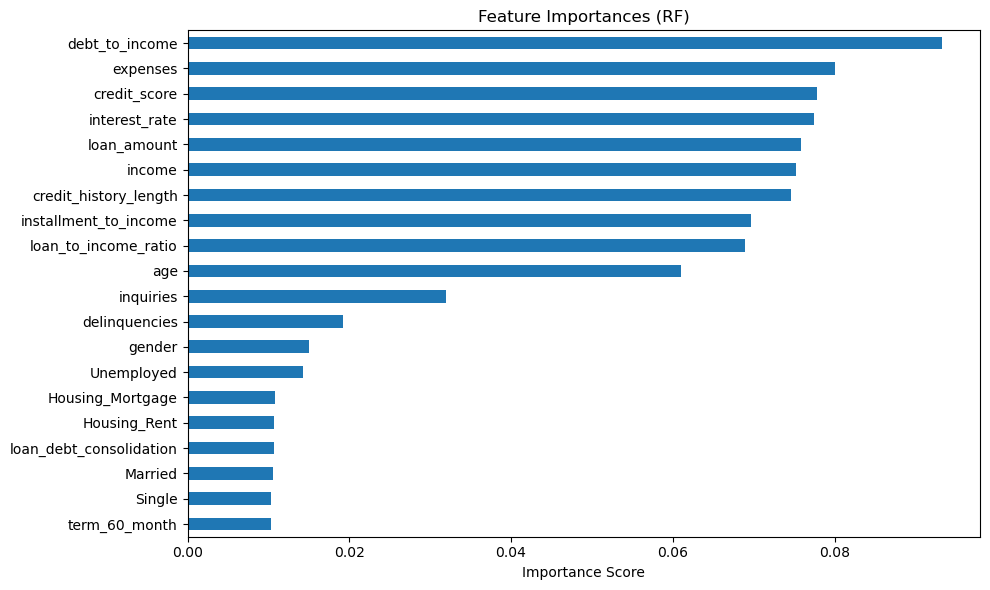

In [243]:
importances_rf = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(10, 6))
importances_rf.tail(20).plot(kind='barh')
plt.title('Feature Importances (RF)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

The plot above displays the feature importances derived from the Random Forest model. Features such as debt_to_income, expenses, and credit_score have the highest importance scores, indicating that they play a significant role in predicting loan default. Other influential variables include interest_rate, loan_amount, and credit_history_length. On the other hand, features like term_60_month, marital status, and housing type show lower importance, suggesting a more limited impact on the model’s decision-making process.

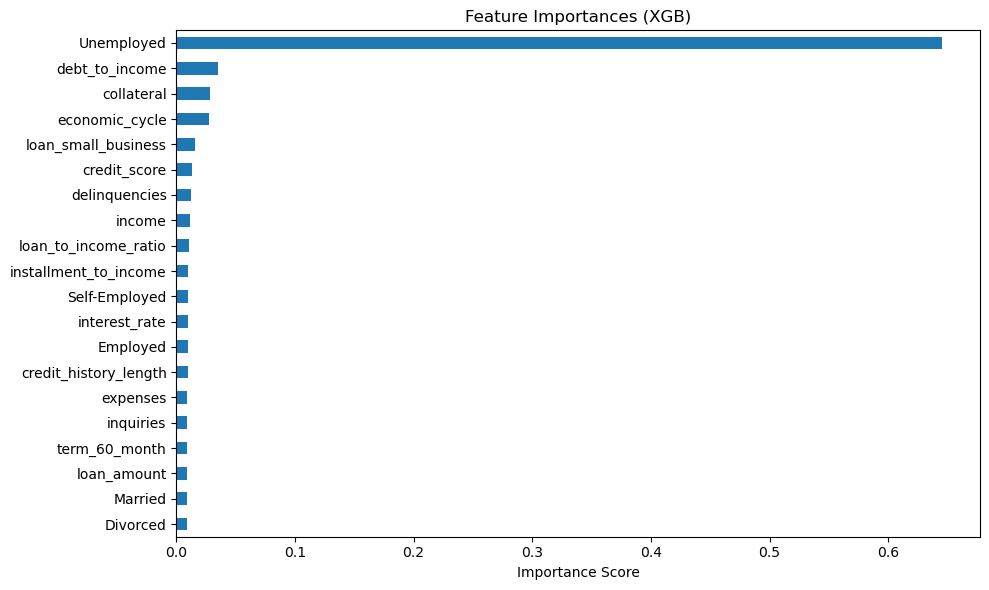

In [244]:
importances_rf = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(10, 6))
importances_rf.tail(20).plot(kind='barh')
plt.title('Feature Importances (XGB)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

The plot above shows the feature importances from the XGBoost model. Unemployed stands out as the most dominant predictor, contributing more than half of the total decision weight. Other important factors include debt_to_income, collateral, and economic_cycle, which also have noticeable influence on model predictions. In contrast, many features such as loan_amount, marital status, and term_60_month show very low importance, indicating limited impact on the XGBoost model’s decisions.

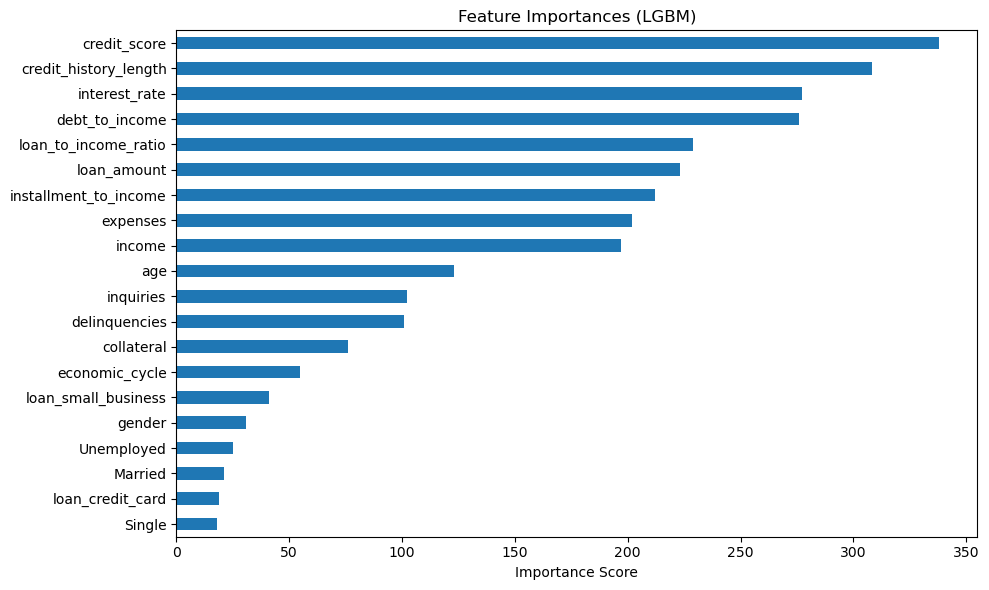

In [245]:
importances_rf = pd.Series(lgbm_model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(10, 6))
importances_rf.tail(20).plot(kind='barh')
plt.title('Feature Importances (LGBM)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

The plot above displays feature importances from the LightGBM model. Credit_score and credit_history_length are the most influential variables, followed closely by interest_rate and debt_to_income, indicating that borrower creditworthiness and loan affordability are key predictors of default. Additional important features include various income-related ratios and loan characteristics. Features such as marital status, unemployment, and specific loan purposes contribute less to the model’s decisions, suggesting their relatively limited predictive value.

In [246]:
# SHAP values for local and global explanation

In [247]:
import shap

In [248]:
# Random Forest

In [249]:
# explainer = shap.TreeExplainer(rf_model)

In [250]:
# shap_values = explainer.shap_values(X_test)

In [251]:
# Global Explanation: SHAP summary plot

In [252]:
# shap.summary_plot(shap_values, X_test)

In [253]:
# SHAP waterfall plot for the first prediction

In [254]:
# shap.force_plot(explainer.expected_value, shap_values[0], X_test.iloc[0])

In [255]:
# XGB

In [256]:
explainer = shap.TreeExplainer(xgb_model)

In [257]:
shap_values = explainer.shap_values(X_test)

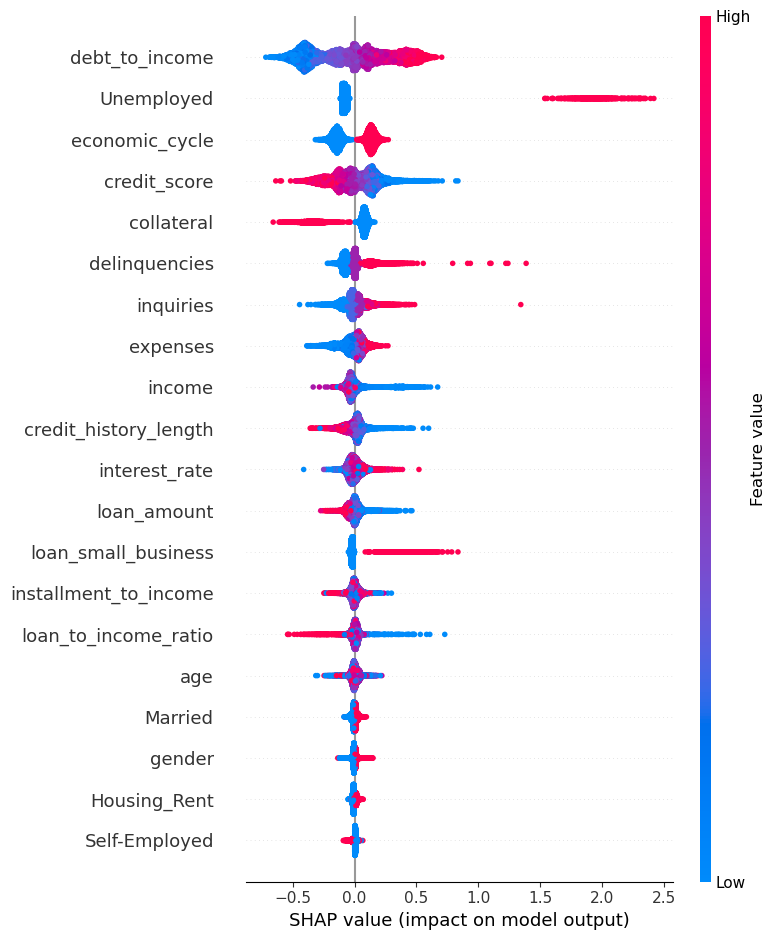

In [258]:
shap.summary_plot(shap_values, X_test)

The SHAP summary plot for the XGBoost model illustrates the global feature importance and how individual features influence default predictions. Features like debt_to_income, Unemployed, and economic_cycle are the most impactful, with high SHAP values indicating a strong push toward default. Each dot represents a single prediction, with color denoting feature value, red for high, blue for low. For example, higher debt-to-income ratios (in red) tend to increase default risk, while high credit scores (also red) pull predictions toward non-default. This plot offers both a ranking of important features and a view of their directional influence on the model output.

In [167]:
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[0], X_test.iloc[0])

The SHAP force plot above visualizes how each feature contributed to the first prediction made by the XGBoost model. The model’s base value (average prediction) starts at approximately -0.30, and the final prediction shifts to -1.17 due to feature contributions.

Features in red pushed the prediction toward default (lower outcome), with economic_cycle, expenses, and debt_to_income being the strongest drivers. In contrast, features in blue pushed the prediction toward non-default, including loan_to_income_ratio, credit_history_length, credit_score, and installment_to_income. This visualization provides a transparent explanation of how individual factors influenced the model’s decision for this specific borrower.

In [259]:
# LGBM

In [260]:
explainer = shap.TreeExplainer(lgbm_model)

In [261]:
shap_values = explainer.shap_values(X_test)

C:\Users\laman\anaconda3\Lib\site-packages\shap\explainers\_tree.py:583: UserWarning:

LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray



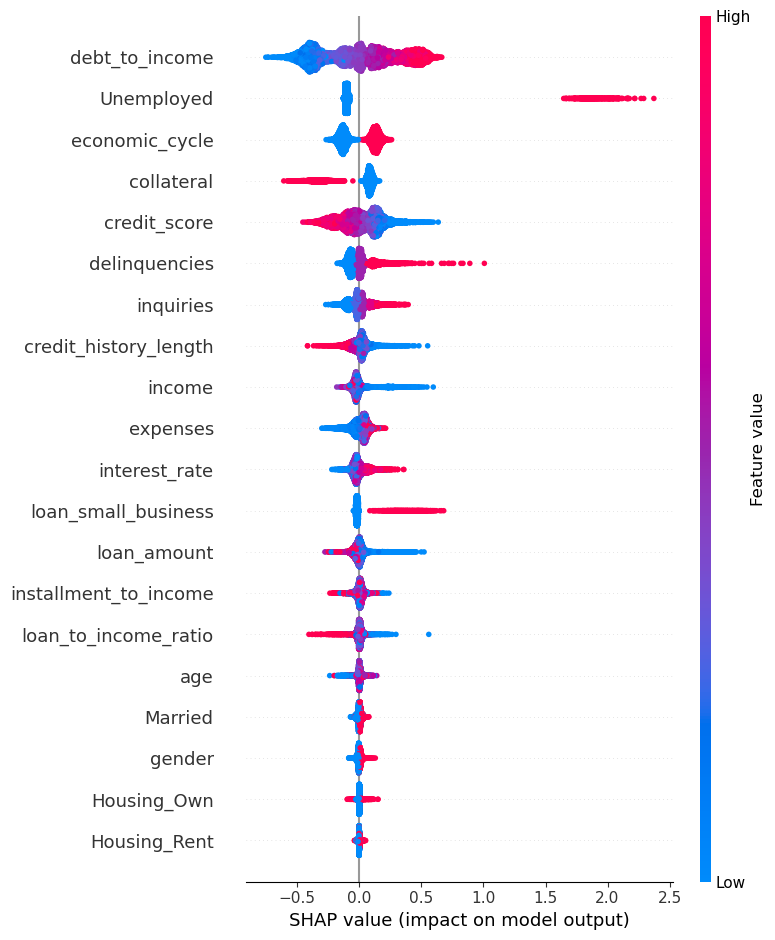

In [262]:
shap.summary_plot(shap_values, X_test)

The SHAP summary plot illustrates the overall influence of each feature on LightGBM’s predictions. Debt-to-income, Unemployed, and economic_cycle have the strongest impact on default predictions. Red dots (high feature values) on the right indicate a push toward higher default risk, while blue dots (low values) on the left suggest lower risk. For example, high debt-to-income ratios and being unemployed push predictions toward default, while high credit scores and presence of collateral reduce the risk. This plot highlights both the importance and directional effect of each feature across all observations.

In [172]:
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[0], X_test.iloc[0])

The SHAP force plot above explains how each feature contributed to this specific prediction. The base value (average model output) was around −0.31, and the final prediction shifted to −1.10, indicating a stronger prediction toward non-default.

Red features on the left, like economic_cycle and debt_to_income, pushed the prediction toward default. However, several strong blue features pulled it in the opposite direction, including loan_to_income_ratio, installment_to_income, credit_history_length, credit_score, and even Unemployed (which in this specific case had a negative impact). Overall, the combination of these features led the model to predict a low default probability for this instance.

In [263]:
# Partial Dependence Plots (PDPs)
#Partial Dependence shows how a feature affects the model's prediction, 
#on average, across the dataset — while keeping all other features fixed.

In [264]:
# RF

In [265]:
from sklearn.inspection import PartialDependenceDisplay

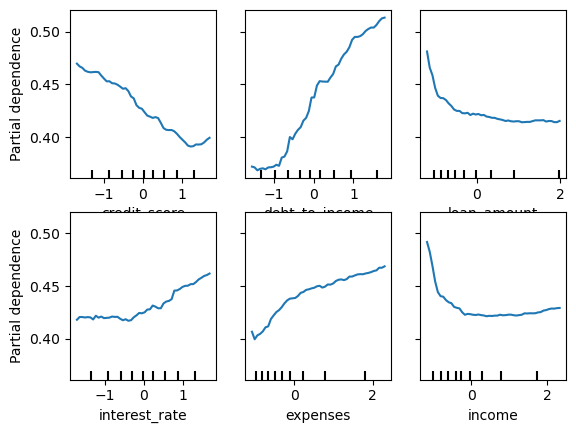

In [266]:
features = ['credit_score', 'debt_to_income', 'loan_amount', 'interest_rate', 'expenses', 'income']

PartialDependenceDisplay.from_estimator(
    estimator=rf_model,
    X=X_test,
    features=features,
    grid_resolution=50,
    kind='average'
)

plt.show()

The partial dependence plots (PDPs) provide insights into how individual features influence the model’s prediction of loan default probability, while keeping all other variables constant. Key observations include:

Credit Score: As credit score increases, the predicted probability of default decreases, reflecting the expected relationship between better creditworthiness and lower risk.

Debt-to-Income Ratio: There is a clear positive association,  higher DTI ratios significantly increase the likelihood of default.

Loan Amount: Smaller loans are associated with slightly higher predicted risk, though this effect diminishes with larger amounts.

Interest Rate: Higher interest rates correlate with increased default risk, likely due to the higher repayment burden.

Expenses: An upward trend indicates that borrowers with higher monthly expenses are more likely to default.

Income: Higher income levels are associated with lower default probabilities, aligning with the assumption that greater earnings improve repayment capacity.

Overall, the PDPs confirm that the model captures logical and interpretable relationships between borrower characteristics and default risk.

In [267]:
#XGB

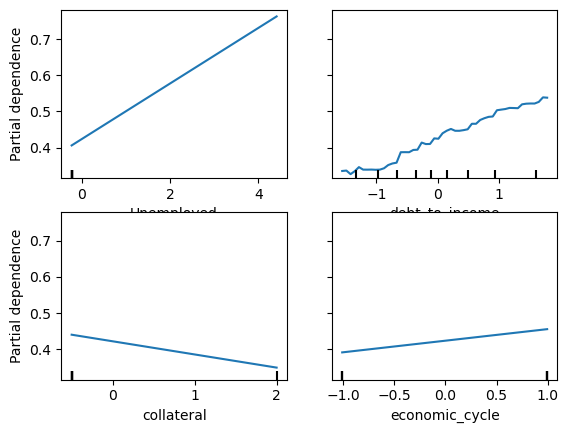

In [271]:
features = ['Unemployed', 'debt_to_income', 'collateral', 'economic_cycle']

PartialDependenceDisplay.from_estimator(
    estimator=xgb_model,
    X=X_test,
    features=features,
    grid_resolution=50,
    kind='average',
    n_cols=2
)

plt.show()

These PDPs illustrate how key features influence the XGBoost model’s predicted default probability, holding all other variables constant:

Unemployed: A clear positive relationship exists—being unemployed substantially increases the predicted likelihood of default, reflecting XGBoost's sensitivity to this high-risk status.

Debt-to-Income Ratio: Default probability rises with higher DTI values, confirming this feature’s strong positive marginal impact on risk.

Collateral: The presence of collateral slightly lowers the default risk, aligning with lending logic—secured loans tend to be safer.

Economic Cycle: Borrowers in a "stressed" economic environment show marginally higher default risk, suggesting XGBoost captures macroeconomic pressure in its predictions.

These plots confirm that XGBoost assigns higher risk to financial strain, unemployment, and stressed economic periods, valuable signals for credit risk assessment.

In [269]:
# LGBM

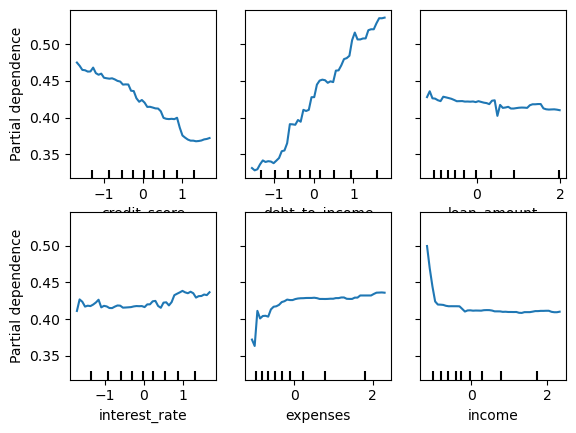

In [270]:
features = ['credit_score', 'debt_to_income', 'loan_amount', 'interest_rate', 'expenses', 'income']

PartialDependenceDisplay.from_estimator(
    estimator=lgbm_model,
    X=X_test,
    features=features,
    grid_resolution=50,
    kind='average'
)

plt.show()

These plots demonstrate how individual features influence the LGBM model’s prediction of loan default probability, assuming all other features are held constant:

Credit Score: There is a clear negative relationship—higher credit scores reduce the default probability, as expected in credit risk modeling.

Debt-to-Income Ratio: A strong upward trend is visible—higher DTI ratios significantly increase the likelihood of default, highlighting borrower overextension.

Loan Amount: The default risk initially rises slightly with loan amount and then levels off, suggesting LGBM learns some nonlinearity but de-emphasizes loan size beyond a point.

Interest Rate: A slight positive trend exists—higher interest rates correlate with increased risk, though the effect is not dramatic.

Expenses: Higher expenses increase the default probability, especially at lower expense levels, where a sharp jump is visible.

Income: There's a steep drop in default risk at very low income levels, but beyond a certain income threshold, additional income doesn’t significantly impact the risk.

LGBM captures nonlinear risk patterns effectively. Creditworthiness (credit score), financial stress (DTI, expenses), and affordability (income) are key drivers of predicted defaults.

#### Deliver insights into:- 
What are the strongest predictors of default?- 

Are there nonlinear effects or thresholds?

**Strongest Predictors of Default**

Across all models and interpretation tools, the most influential predictors of loan default are:

Debt-to-Income Ratio: Consistently ranked highest in SHAP, PDPs, and feature importance plots. Higher DTI is strongly associated with a greater risk of default.

Employment Status – Unemployed: Both SHAP and logistic regression coefficients show that being unemployed significantly increases the likelihood of default.

Credit Score: Lower credit scores are associated with higher default risk. This is evident in both SHAP and PDPs.

Economic Cycle (Stressed vs. Stable): Applicants during stressed periods (e.g., year 2024) have a higher likelihood of default.

Collateral: Presence of collateral decreases default probability, particularly highlighted in tree models and SHAP plots.

Loan Purpose – Small Business: Loans for small business purposes show elevated default rates in both aggregated default analysis and model attributions.

**Nonlinear Effects and Thresholds**

Partial Dependence Plots (PDPs) and SHAP values revealed several important nonlinear patterns:

Debt-to-Income Ratio: Risk increases steeply as DTI surpasses a certain threshold (~0.4), suggesting a non-linear escalation in default likelihood.

Credit Score: Shows a non-linear decreasing relationship—default risk decreases rapidly up to ~700, then levels off.

Income: Displays a diminishing effect—higher income reduces risk up to a point, but the marginal benefit lessens as income grows.

Interest Rate: A gradual increase in default risk is observed with rising interest rates, again showing a nonlinear pattern.

Collateral: A binary effect is observed—having collateral significantly lowers default probability.

Economic Cycle: Default rates are higher in the 'Stressed' cycle, regardless of other features.

# 8. PD Calibration

### 8.1 Platt Scaling (logistic calibration)

In [273]:
from sklearn.calibration import CalibratedClassifierCV

In [275]:
log_reg_calibrated = CalibratedClassifierCV(base_estimator=log_reg_model, method='sigmoid', cv=5)
log_reg_calibrated.fit(X_train, y_train)

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\calibration.py:321: FutureWarning:

`base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.



CalibratedClassifierCV(base_estimator=LogisticRegression(max_iter=1000,
                                                         random_state=42,
                                                         solver='liblinear'),
                       cv=5)

In [276]:
xgb_calibrated = CalibratedClassifierCV(base_estimator=xgb_model, method='sigmoid', cv=5)
xgb_calibrated.fit(X_train, y_train)

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\calibration.py:321: FutureWarning:

`base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.

C:\Users\laman\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning:

[20:49:59] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0015a694724fa8361-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.


C:\Users\laman\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning:

[20:49:59] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0015a694724fa8361-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.


C:\Users\laman\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning:

[20:50:00] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0015a694724fa8361-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_

CalibratedClassifierCV(base_estimator=XGBClassifier(base_score=None,
                                                    booster=None,
                                                    callbacks=None,
                                                    colsample_bylevel=None,
                                                    colsample_bynode=None,
                                                    colsample_bytree=None,
                                                    device=None,
                                                    early_stopping_rounds=None,
                                                    enable_categorical=False,
                                                    eval_metric='logloss',
                                                    feature_types=None,
                                                    gamma=None,
                                                    grow_policy=None,
                                                    importance_type=None,
                                                    interaction_constraints=None,
                                                    learning_rate=0.1,
                                                    max_bin=None,
                                                    max_cat_threshold=None,
                                                    max_cat_to_onehot=None,
                                                    max_delta_step=None,
                                                    max_depth=6,
                                                    max_leaves=None,
                                                    min_child_weight=None,
                                                    missing=nan,
                                                    monotone_constraints=None,
                                                    multi_strategy=None,
                                                    n_estimators=100,
                                                    n_jobs=None,
                                                    num_parallel_tree=None,
                                                    random_state=42, ...),
                       cv=5)

In [277]:
lgbm_calibrated = CalibratedClassifierCV(base_estimator=lgbm_model, method='sigmoid', cv=5)
lgbm_calibrated.fit(X_train, y_train)

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\calibration.py:321: FutureWarning:

`base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.



[LightGBM] [Info] Number of positive: 13581, number of negative: 18375
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002205 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2419
[LightGBM] [Info] Number of data points in the train set: 31956, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.424991 -> initscore=-0.302319
[LightGBM] [Info] Start training from score -0.302319
[LightGBM] [Info] Number of positive: 13582, number of negative: 18375
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002237 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2416
[LightGBM] [Info] Number of data points in the train set: 31957, number of used features: 34
[LightGBM] [Info] 

CalibratedClassifierCV(base_estimator=LGBMClassifier(random_state=42), cv=5)

In [278]:
rf_calibrated = CalibratedClassifierCV(base_estimator=rf_model, method='sigmoid', cv=5)
rf_calibrated.fit(X_train, y_train)

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\calibration.py:321: FutureWarning:

`base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.



CalibratedClassifierCV(base_estimator=RandomForestClassifier(random_state=42),
                       cv=5)

### 8.2 Isotonic Regression (non-parametric)

In [279]:
log_reg_isotonic = CalibratedClassifierCV(base_estimator=log_reg_model, method='isotonic', cv=5)
log_reg_isotonic.fit(X_train, y_train)

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\calibration.py:321: FutureWarning:

`base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.



CalibratedClassifierCV(base_estimator=LogisticRegression(max_iter=1000,
                                                         random_state=42,
                                                         solver='liblinear'),
                       cv=5, method='isotonic')

In [280]:
xgb_isotonic = CalibratedClassifierCV(base_estimator=xgb_model, method='isotonic', cv=5)
xgb_isotonic.fit(X_train, y_train)

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\calibration.py:321: FutureWarning:

`base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.

C:\Users\laman\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning:

[20:52:11] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0015a694724fa8361-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.


C:\Users\laman\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning:

[20:52:12] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0015a694724fa8361-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.


C:\Users\laman\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning:

[20:52:12] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0015a694724fa8361-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_

CalibratedClassifierCV(base_estimator=XGBClassifier(base_score=None,
                                                    booster=None,
                                                    callbacks=None,
                                                    colsample_bylevel=None,
                                                    colsample_bynode=None,
                                                    colsample_bytree=None,
                                                    device=None,
                                                    early_stopping_rounds=None,
                                                    enable_categorical=False,
                                                    eval_metric='logloss',
                                                    feature_types=None,
                                                    gamma=None,
                                                    grow_policy=None,
                                                    importance_type=None,
                                                    interaction_constraints=None,
                                                    learning_rate=0.1,
                                                    max_bin=None,
                                                    max_cat_threshold=None,
                                                    max_cat_to_onehot=None,
                                                    max_delta_step=None,
                                                    max_depth=6,
                                                    max_leaves=None,
                                                    min_child_weight=None,
                                                    missing=nan,
                                                    monotone_constraints=None,
                                                    multi_strategy=None,
                                                    n_estimators=100,
                                                    n_jobs=None,
                                                    num_parallel_tree=None,
                                                    random_state=42, ...),
                       cv=5, method='isotonic')

In [281]:
lgbm_isotonic = CalibratedClassifierCV(base_estimator=lgbm_model, method='isotonic', cv=5)
lgbm_isotonic.fit(X_train, y_train)

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\calibration.py:321: FutureWarning:

`base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.



[LightGBM] [Info] Number of positive: 13581, number of negative: 18375
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002225 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2419
[LightGBM] [Info] Number of data points in the train set: 31956, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.424991 -> initscore=-0.302319
[LightGBM] [Info] Start training from score -0.302319
[LightGBM] [Info] Number of positive: 13582, number of negative: 18375
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002250 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2416
[LightGBM] [Info] Number of data points in the train set: 31957, number of used features: 34
[LightGBM] [Info] 

CalibratedClassifierCV(base_estimator=LGBMClassifier(random_state=42), cv=5,
                       method='isotonic')

In [282]:
rf_isotonic = CalibratedClassifierCV(base_estimator=rf_model, method='isotonic', cv=5)
rf_isotonic.fit(X_train, y_train)

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\calibration.py:321: FutureWarning:

`base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.



CalibratedClassifierCV(base_estimator=RandomForestClassifier(random_state=42),
                       cv=5, method='isotonic')

### 8.3 Visual diagnostics:

#### 8.3.1 Calibration curve

In [283]:
from sklearn.calibration import calibration_curve

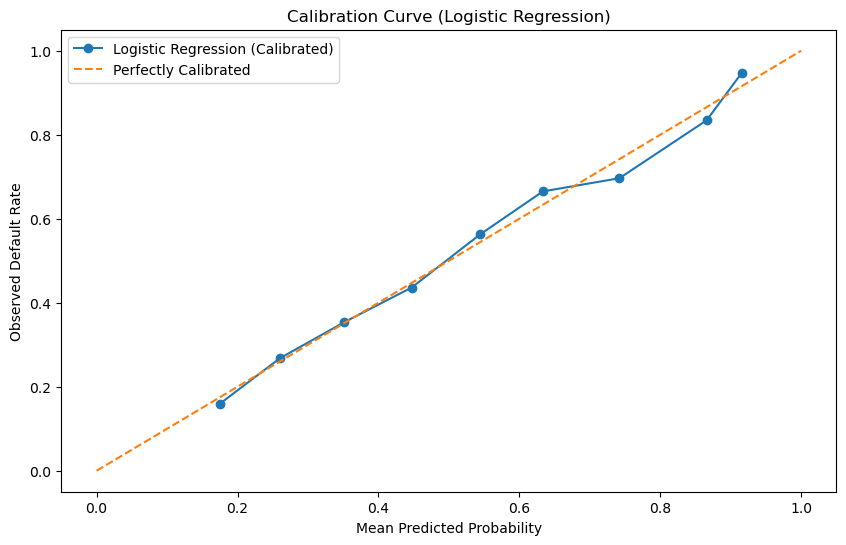

In [286]:
y_prob = log_reg_calibrated.predict_proba(X_test)[:, 1]

prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

plt.figure(figsize=(10, 6))
plt.plot(prob_pred, prob_true, marker='o', label='Logistic Regression (Calibrated)')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Default Rate')
plt.title('Calibration Curve (Logistic Regression)')
plt.legend()
plt.show()

The calibration curve for the Logistic Regression model illustrates a strong alignment between the predicted probabilities and the actual observed default rates. The model’s curve closely follows the diagonal reference line representing perfect calibration. This indicates that when the model predicts a certain probability of default, the observed frequency of default among those predictions is very similar. For instance, predicted probabilities around 0.6 correspond to an observed default rate of approximately 60%, confirming the model’s reliability in estimating true risk. Overall, the Logistic Regression model demonstrates well-calibrated probability outputs, making it suitable for use in risk-sensitive applications such as credit scoring.

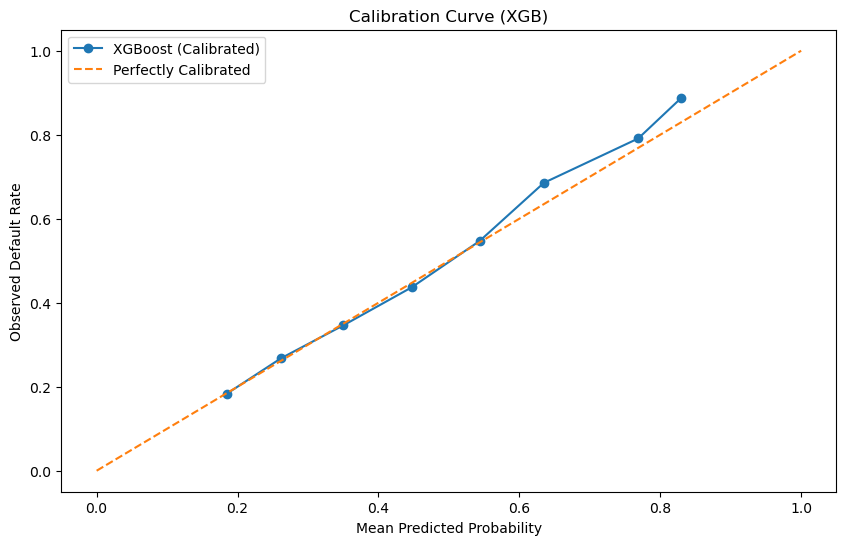

In [292]:
y_prob = xgb_calibrated.predict_proba(X_test)[:, 1]

prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

plt.figure(figsize=(10, 6))
plt.plot(prob_pred, prob_true, marker='o', label='XGBoost (Calibrated)')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Default Rate')
plt.title('Calibration Curve (XGB)')
plt.legend()
plt.show()

The calibration curve for the XGBoost model shows that its predicted probabilities are generally well-aligned with the observed default rates. For most of the range, the model’s curve closely tracks the diagonal reference line representing perfect calibration, indicating accurate probability estimation. However, at the higher probability bins (above 0.7), the curve slightly deviates above the diagonal, suggesting that XGBoost tends to slightly overestimate risk at these high-confidence levels. Despite this, the model maintains good overall calibration, making its probability outputs reliable for risk assessment purposes.

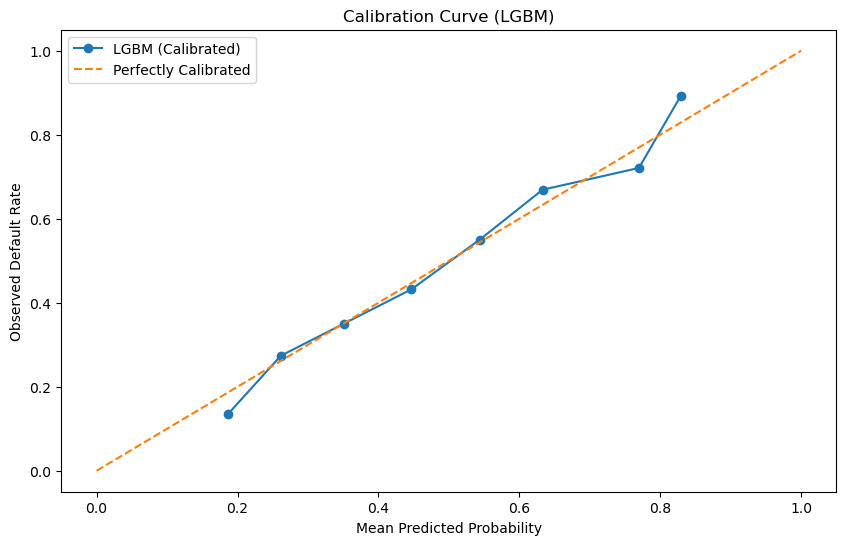

In [303]:
y_prob = lgbm_calibrated.predict_proba(X_test)[:, 1]

prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

plt.figure(figsize=(10, 6))
plt.plot(prob_pred, prob_true, marker='o', label='LGBM (Calibrated)')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Default Rate')
plt.title('Calibration Curve (LGBM)')
plt.legend()
plt.show()

The calibration curve for the LightGBM model shows that its predicted probabilities are fairly well-calibrated across most probability bins. The curve generally tracks the ideal diagonal line, indicating a good match between predicted and actual default rates. However, in higher probability ranges (above 0.75), the curve slightly overshoots the reference line, suggesting LightGBM overestimates default risk at those levels. Despite minor deviations, the model demonstrates reliable probability estimates and solid calibration performance for most of the prediction range.

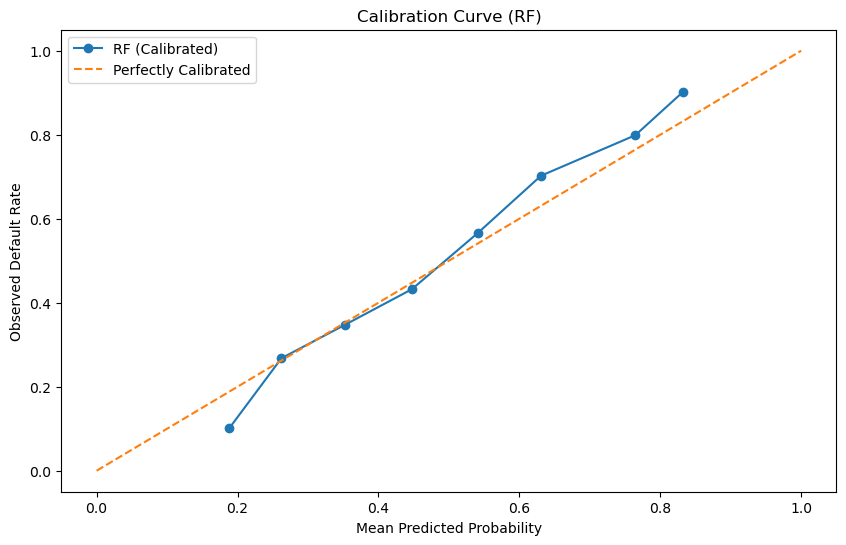

In [304]:
y_prob = rf_calibrated.predict_proba(X_test)[:, 1]

prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

plt.figure(figsize=(10, 6))
plt.plot(prob_pred, prob_true, marker='o', label='RF (Calibrated)')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Default Rate')
plt.title('Calibration Curve (RF)')
plt.legend()
plt.show()

The calibration curve for the Random Forest model shows a strong alignment with the ideal diagonal, indicating that the model’s predicted probabilities closely match the actual observed default rates across most bins. There is a slight overestimation in higher probability ranges (above 0.75), but overall, the model demonstrates good calibration quality. This suggests that the Random Forest model provides reliable probability estimates, making it a trustworthy choice for risk-based decision-making.

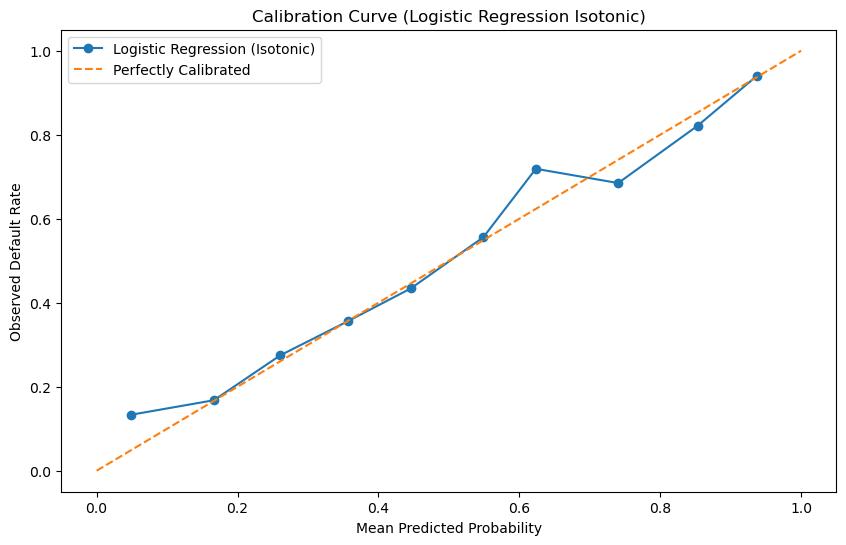

In [305]:
y_prob = log_reg_isotonic.predict_proba(X_test)[:, 1]

prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

plt.figure(figsize=(10, 6))
plt.plot(prob_pred, prob_true, marker='o', label='Logistic Regression (Isotonic)')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Default Rate')
plt.title('Calibration Curve (Logistic Regression Isotonic)')
plt.legend()
plt.show()

The calibration curve for the Logistic Regression model using Isotonic Regression shows strong alignment with the perfectly calibrated line, particularly in the mid-range of predicted probabilities (around 0.3 to 0.8). Some minor deviations appear at the lower and higher ends, but overall, the curve closely follows the diagonal. This indicates that isotonic calibration effectively improves the reliability of probability estimates from logistic regression, especially in areas where raw probabilities might have previously underestimated or overestimated the actual risk.

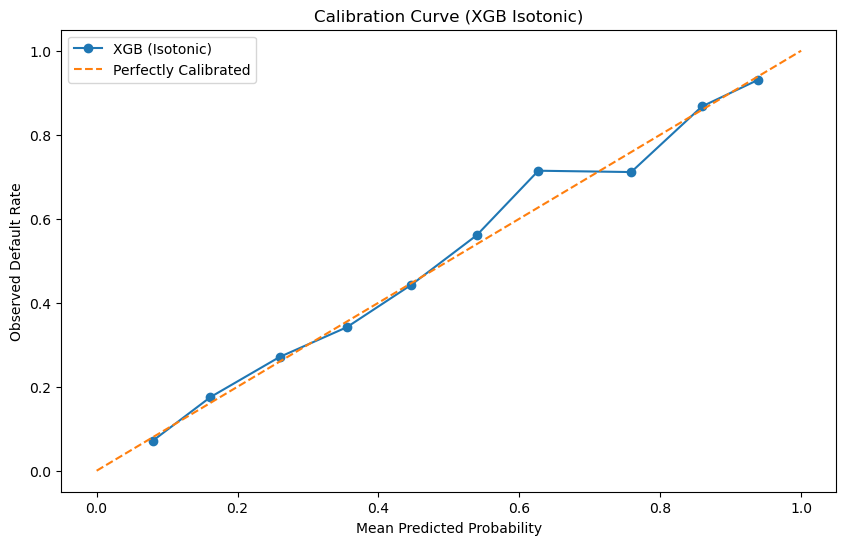

In [306]:
y_prob = xgb_isotonic.predict_proba(X_test)[:, 1]

prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

plt.figure(figsize=(10, 6))
plt.plot(prob_pred, prob_true, marker='o', label='XGB (Isotonic)')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Default Rate')
plt.title('Calibration Curve (XGB Isotonic)')
plt.legend()
plt.show()

The calibration curve for the XGBoost model using Isotonic Regression shows a strong alignment with the perfectly calibrated line across the full range of predicted probabilities. Most points fall close to the diagonal, indicating well-calibrated probability estimates. While slight overprediction appears in the mid to high ranges, the curve remains consistent overall. This suggests that isotonic calibration improves the reliability of XGBoost’s predicted default probabilities, making them better aligned with actual observed default rates.

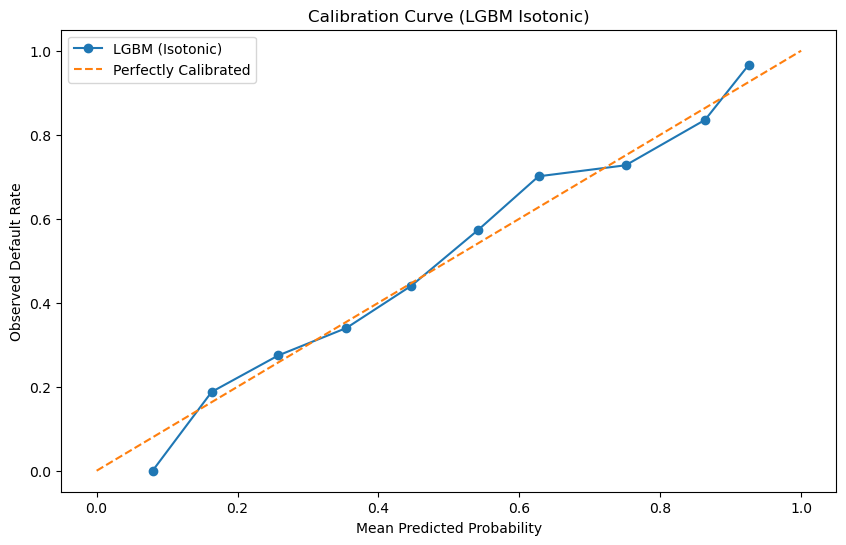

In [307]:
y_prob = lgbm_isotonic.predict_proba(X_test)[:, 1]

prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

plt.figure(figsize=(10, 6))
plt.plot(prob_pred, prob_true, marker='o', label='LGBM (Isotonic)')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Default Rate')
plt.title('Calibration Curve (LGBM Isotonic)')
plt.legend()
plt.show()

The calibration curve for the LGBM model with Isotonic Regression shows a strong alignment with the perfectly calibrated line across most probability ranges. Predicted probabilities closely match observed default rates, especially between 0.2 and 0.9. There is a slight underestimation at the very low end and slight overestimation above 0.9, but overall the model is well calibrated. Isotonic regression has improved LGBM’s probability reliability, making it a strong choice when precise default probability estimates are important.

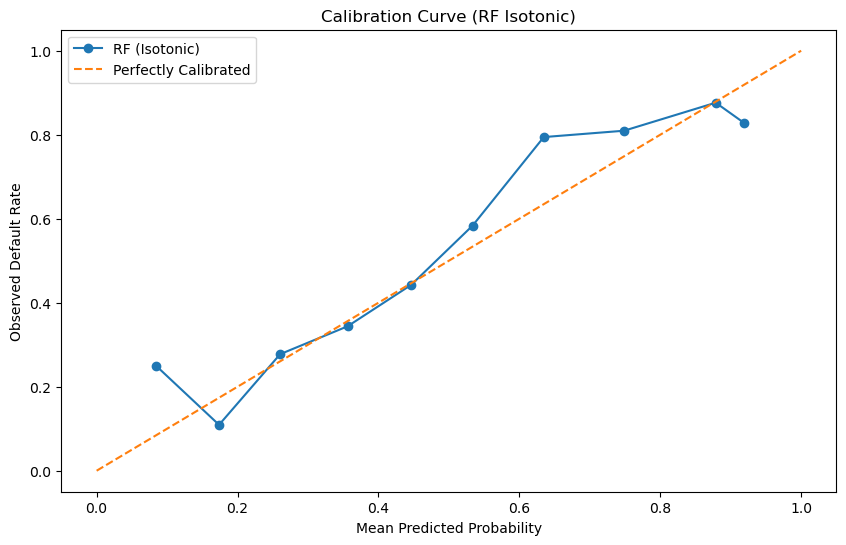

In [308]:
y_prob = rf_isotonic.predict_proba(X_test)[:, 1]

prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

plt.figure(figsize=(10, 6))
plt.plot(prob_pred, prob_true, marker='o', label='RF (Isotonic)')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Default Rate')
plt.title('Calibration Curve (RF Isotonic)')
plt.legend()
plt.show()

The calibration curve for the Random Forest model with Isotonic Regression reveals moderate calibration. While predictions above 0.5 align reasonably well with observed default rates, there’s more variability at lower probability bins, some points deviate below or above the ideal diagonal. This suggests the model slightly over- or underestimates risk in low probability regions. Although calibration improves overall reliability, the Random Forest still exhibits less consistent probability estimates compared to models like LGBM.

#### 8.3.2 Binned PD vs actual default rate (deciles or buckets)

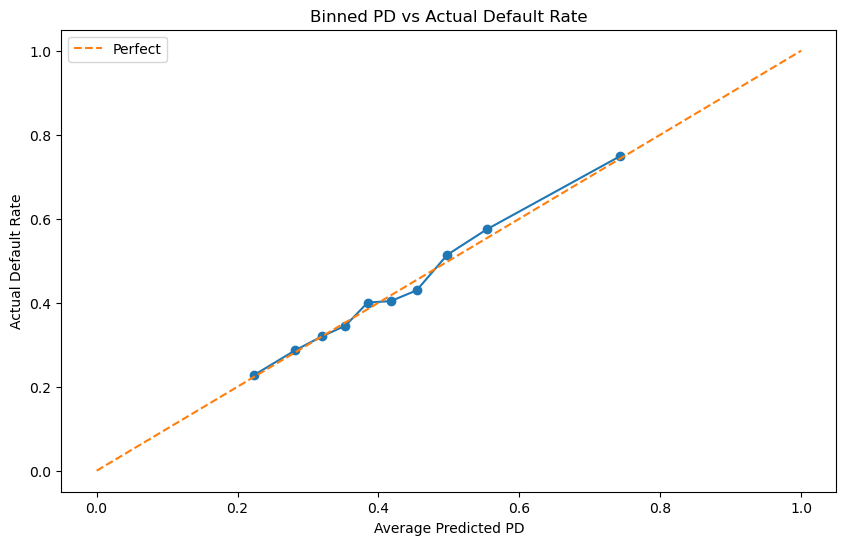

In [318]:
y_prob = log_reg_calibrated.predict_proba(X_test)[:, 1]

pd_bins = pd.qcut(y_prob, q=10, labels=False)

calibration_df = pd.DataFrame({'pred_prob': y_prob, 'actual': y_test, 'bin': pd_bins})

bucket_avg = calibration_df.groupby('bin').agg(
    avg_pred=('pred_prob', 'mean'),
    actual_rate=('actual', 'mean')
).reset_index()

plt.figure(figsize=(10,6))
plt.plot(bucket_avg['avg_pred'], bucket_avg['actual_rate'], marker='o')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfect')
plt.xlabel('Average Predicted PD')
plt.ylabel('Actual Default Rate')
plt.title('Binned PD vs Actual Default Rate')
plt.legend()
plt.show()

This binned plot for the calibrated Logistic Regression model compares predicted probabilities (PD) to actual default rates across deciles. The points closely follow the orange diagonal, indicating a strong alignment between predicted and observed default rates. This suggests the model is well-calibrated, its probability outputs meaningfully reflect actual risk. Thus, when Logistic Regression predicts a 60% chance of default, roughly 60% of those cases do default in reality. This enhances the model's reliability for decision-making in credit risk.

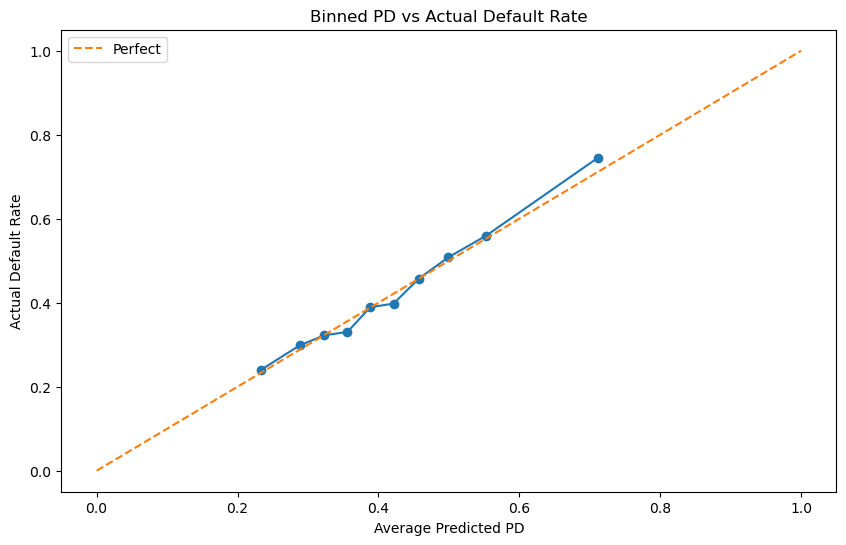

In [311]:
y_prob = xgb_calibrated.predict_proba(X_test)[:, 1]

pd_bins = pd.qcut(y_prob, q=10, labels=False)

calibration_df = pd.DataFrame({'pred_prob': y_prob, 'actual': y_test, 'bin': pd_bins})

bucket_avg = calibration_df.groupby('bin').agg(
    avg_pred=('pred_prob', 'mean'),
    actual_rate=('actual', 'mean')
).reset_index()

plt.figure(figsize=(10,6))
plt.plot(bucket_avg['avg_pred'], bucket_avg['actual_rate'], marker='o')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfect')
plt.xlabel('Average Predicted PD')
plt.ylabel('Actual Default Rate')
plt.title('Binned PD vs Actual Default Rate')
plt.legend()
plt.show()

This binned PD vs. actual default rate plot for the calibrated XGBoost model shows strong alignment with the ideal (orange) line, indicating well-calibrated probability estimates. Most bins lie very close to the diagonal, suggesting that the predicted probability of default corresponds closely to the observed default rate across the probability spectrum. This consistency implies that the XGBoost model, after Platt scaling, is providing reliable risk estimates, which is essential for downstream credit decisioning and risk-based pricing strategies.

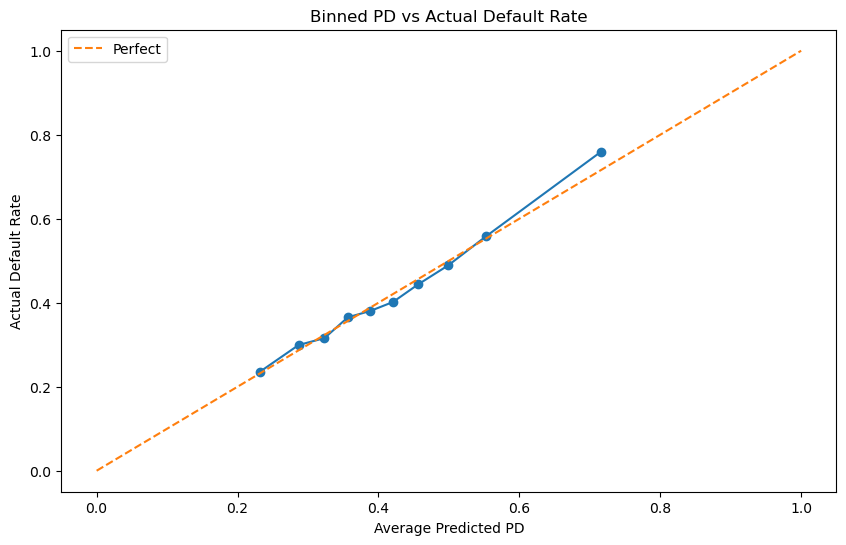

In [312]:
y_prob = lgbm_calibrated.predict_proba(X_test)[:, 1]

pd_bins = pd.qcut(y_prob, q=10, labels=False)

calibration_df = pd.DataFrame({'pred_prob': y_prob, 'actual': y_test, 'bin': pd_bins})

bucket_avg = calibration_df.groupby('bin').agg(
    avg_pred=('pred_prob', 'mean'),
    actual_rate=('actual', 'mean')
).reset_index()

plt.figure(figsize=(10,6))
plt.plot(bucket_avg['avg_pred'], bucket_avg['actual_rate'], marker='o')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfect')
plt.xlabel('Average Predicted PD')
plt.ylabel('Actual Default Rate')
plt.title('Binned PD vs Actual Default Rate')
plt.legend()
plt.show()

This binned PD vs. actual default rate plot for the calibrated LightGBM model shows excellent alignment with the perfect calibration line, particularly across the mid-range probabilities. The predicted PDs correspond very closely to the observed default rates, with only slight deviation at the higher end. This suggests that LightGBM, after calibration, provides highly reliable probability estimates, making it suitable for risk-based decision-making and threshold-based strategies in credit scoring.

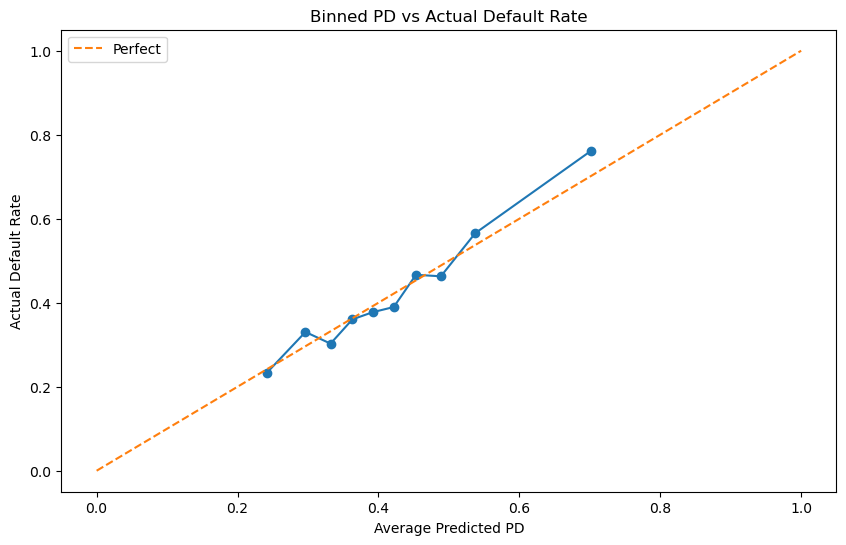

In [313]:
y_prob = rf_calibrated.predict_proba(X_test)[:, 1]

pd_bins = pd.qcut(y_prob, q=10, labels=False)

calibration_df = pd.DataFrame({'pred_prob': y_prob, 'actual': y_test, 'bin': pd_bins})

bucket_avg = calibration_df.groupby('bin').agg(
    avg_pred=('pred_prob', 'mean'),
    actual_rate=('actual', 'mean')
).reset_index()

plt.figure(figsize=(10,6))
plt.plot(bucket_avg['avg_pred'], bucket_avg['actual_rate'], marker='o')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfect')
plt.xlabel('Average Predicted PD')
plt.ylabel('Actual Default Rate')
plt.title('Binned PD vs Actual Default Rate')
plt.legend()
plt.show()

This plot shows the binned predicted probability of default (PD) versus actual default rate for the calibrated Random Forest model. The curve aligns fairly well with the perfect calibration line, particularly in the mid-probability range. However, some deviations are visible, especially in the lower and middle buckets, indicating slight over- or underestimation of risk in those segments. Overall, the model shows reasonable calibration, but further tuning or an alternative calibration method like isotonic regression might yield improved reliability for PD estimates.

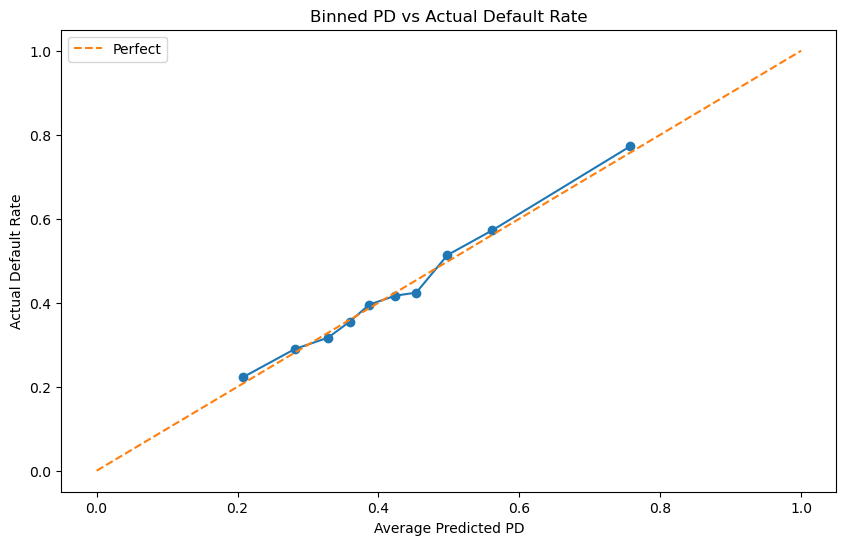

In [314]:
y_prob = log_reg_isotonic.predict_proba(X_test)[:, 1]

pd_bins = pd.qcut(y_prob, q=10, labels=False)

calibration_df = pd.DataFrame({'pred_prob': y_prob, 'actual': y_test, 'bin': pd_bins})

bucket_avg = calibration_df.groupby('bin').agg(
    avg_pred=('pred_prob', 'mean'),
    actual_rate=('actual', 'mean')
).reset_index()

plt.figure(figsize=(10,6))
plt.plot(bucket_avg['avg_pred'], bucket_avg['actual_rate'], marker='o')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfect')
plt.xlabel('Average Predicted PD')
plt.ylabel('Actual Default Rate')
plt.title('Binned PD vs Actual Default Rate')
plt.legend()
plt.show()

This binned PD vs. actual default rate plot illustrates the calibration performance of the Logistic Regression model after applying isotonic regression. The blue line closely follows the orange perfect calibration line across all probability bins, indicating that the calibrated probabilities are well-aligned with observed default rates. This suggests isotonic regression has effectively adjusted the model’s output, improving its reliability for risk estimation and making it a strong candidate for credit scoring use cases.

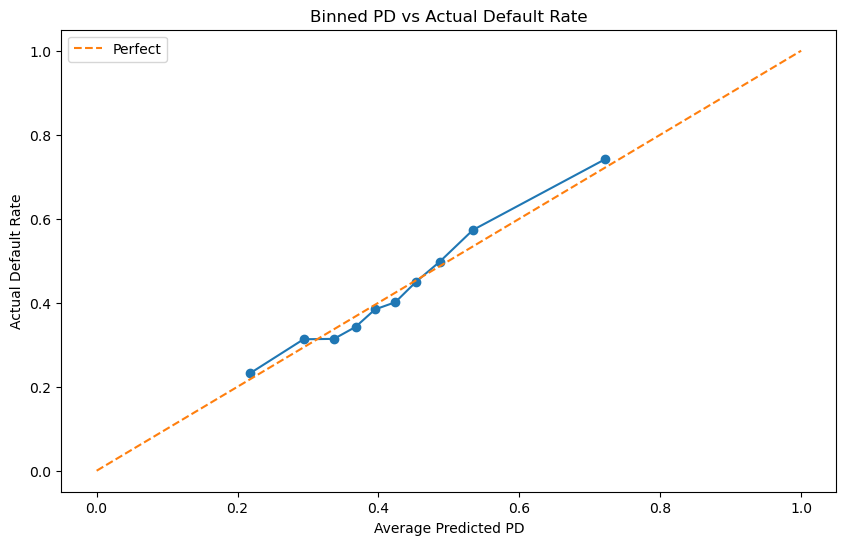

In [315]:
y_prob = xgb_isotonic.predict_proba(X_test)[:, 1]

pd_bins = pd.qcut(y_prob, q=10, labels=False)

calibration_df = pd.DataFrame({'pred_prob': y_prob, 'actual': y_test, 'bin': pd_bins})

bucket_avg = calibration_df.groupby('bin').agg(
    avg_pred=('pred_prob', 'mean'),
    actual_rate=('actual', 'mean')
).reset_index()

plt.figure(figsize=(10,6))
plt.plot(bucket_avg['avg_pred'], bucket_avg['actual_rate'], marker='o')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfect')
plt.xlabel('Average Predicted PD')
plt.ylabel('Actual Default Rate')
plt.title('Binned PD vs Actual Default Rate')
plt.legend()
plt.show()

This binned PD vs. actual default rate plot shows the calibration performance of the XGBoost model after isotonic regression. The blue line tracks the perfect calibration line closely, with only minor deviations at higher predicted probabilities. This suggests that the model’s predicted probabilities are well-aligned with actual default rates across most bins. Overall, the XGBoost model benefits from isotonic calibration and yields reliable PD estimates suitable for risk assessment.

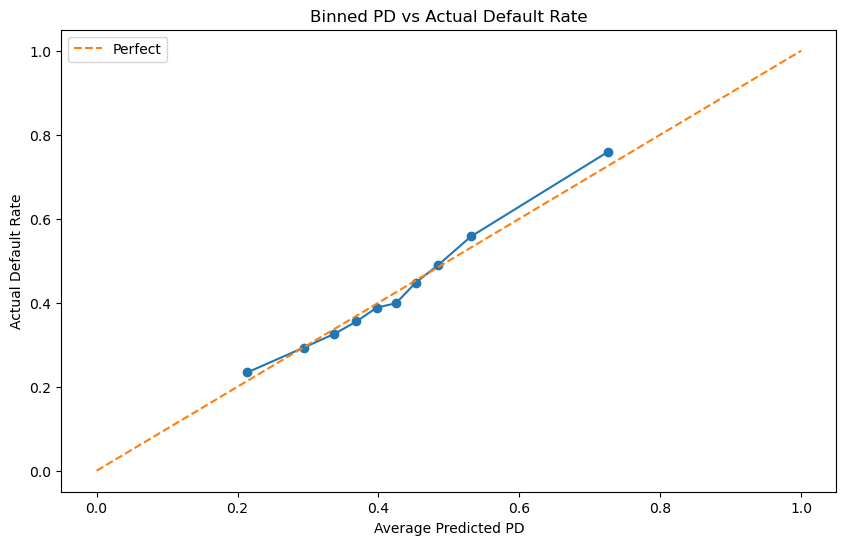

In [316]:
y_prob = lgbm_isotonic.predict_proba(X_test)[:, 1]

pd_bins = pd.qcut(y_prob, q=10, labels=False)

calibration_df = pd.DataFrame({'pred_prob': y_prob, 'actual': y_test, 'bin': pd_bins})

bucket_avg = calibration_df.groupby('bin').agg(
    avg_pred=('pred_prob', 'mean'),
    actual_rate=('actual', 'mean')
).reset_index()

plt.figure(figsize=(10,6))
plt.plot(bucket_avg['avg_pred'], bucket_avg['actual_rate'], marker='o')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfect')
plt.xlabel('Average Predicted PD')
plt.ylabel('Actual Default Rate')
plt.title('Binned PD vs Actual Default Rate')
plt.legend()
plt.show()

This binned PD vs. actual default rate plot for the LGBM model (after isotonic calibration) shows a close alignment between predicted probabilities and actual default rates. The blue curve closely tracks the ideal calibration line, indicating that LGBM’s probability estimates are well-calibrated across all bins. This suggests the model produces reliable PD outputs that reflect true default likelihoods, particularly useful for downstream credit risk decisions.

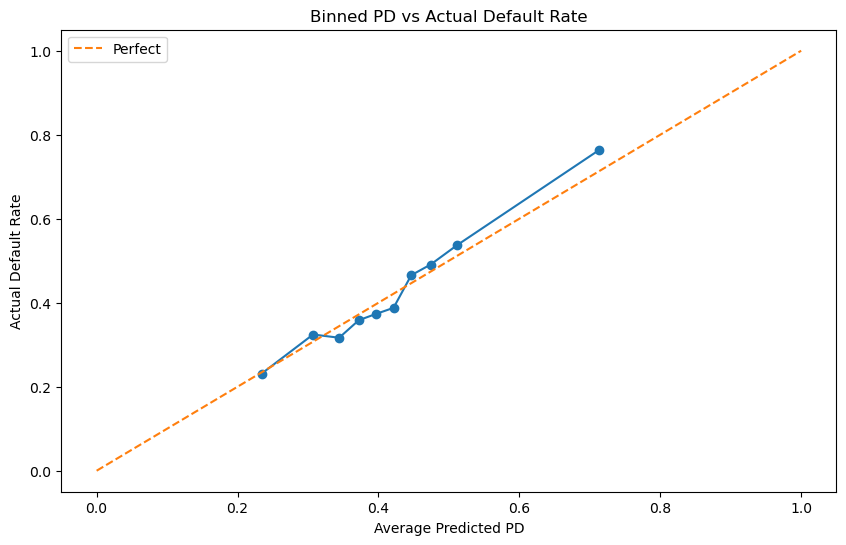

In [317]:
y_prob = rf_isotonic.predict_proba(X_test)[:, 1]

pd_bins = pd.qcut(y_prob, q=10, labels=False)

calibration_df = pd.DataFrame({'pred_prob': y_prob, 'actual': y_test, 'bin': pd_bins})

bucket_avg = calibration_df.groupby('bin').agg(
    avg_pred=('pred_prob', 'mean'),
    actual_rate=('actual', 'mean')
).reset_index()

plt.figure(figsize=(10,6))
plt.plot(bucket_avg['avg_pred'], bucket_avg['actual_rate'], marker='o')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfect')
plt.xlabel('Average Predicted PD')
plt.ylabel('Actual Default Rate')
plt.title('Binned PD vs Actual Default Rate')
plt.legend()
plt.show()

This binned PD vs. actual default rate plot for the Random Forest (RF) model after isotonic calibration indicates a strong alignment between predicted and actual default rates. Most points closely follow the diagonal “perfect” line, suggesting that the calibrated RF model provides well-calibrated probabilities. The plot confirms that, across PD bins, the model’s risk estimates are consistent with actual outcomes, supporting its reliability for probability-based credit risk applications.

# 9. Risk-Based Strategy Simulation

### 9.1 Score Borrowers - Predict probability of default (PD) for all applicants

In [392]:
X_scaled = scaler.transform(X)

In [438]:
pd_scores = log_reg_isotonic.predict_proba(X_scaled)[:, 1]

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\base.py:439: UserWarning:

X does not have valid feature names, but LogisticRegression was fitted with feature names

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\base.py:439: UserWarning:

X does not have valid feature names, but LogisticRegression was fitted with feature names

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\base.py:439: UserWarning:

X does not have valid feature names, but LogisticRegression was fitted with feature names

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\base.py:439: UserWarning:

X does not have valid feature names, but LogisticRegression was fitted with feature names

C:\Users\laman\anaconda3\Lib\site-packages\sklearn\base.py:439: UserWarning:

X does not have valid feature names, but LogisticRegression was fitted with feature names



In [439]:
pd_scores

array([0.5752722 , 0.77852279, 0.36697561, ..., 0.41956179, 0.50694525,
       0.20948104])

In [440]:
df['PD'] = pd_scores

### 9.2 Segment into Risk Bands

In [441]:
df['Risk_Band'] = pd.qcut(df['PD'], q=[0, 0.05, 0.15, 1], labels=['Low', 'Medium', 'High'])

### 9.3 Simulate Business Strategies

Let’s assume:

Reject high-risk applicants.

Add margin for medium-risk (you could simulate higher interest or fees).

Accept low-risk.

Simulate expected loss:

In [442]:
# Loss Given Default (50%)
LGD = 0.5
# Exposure at Default
EAD = df['loan_amount']

df['Expected_Loss'] = df['PD'] * LGD * EAD

### 9.4 Visualizations

#### 9.4.1 PD vs Actual Default Rate (per decile)

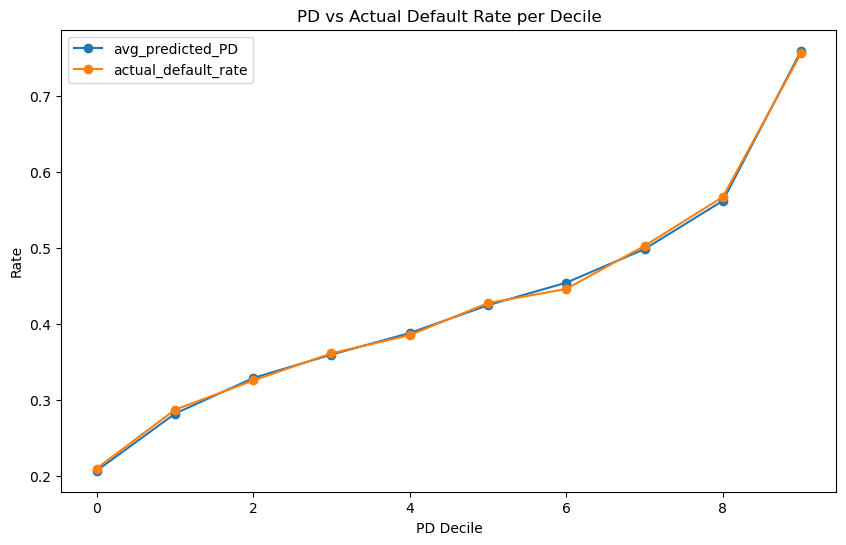

In [443]:
df['PD_decile'] = pd.qcut(df['PD'], 10, labels=False)

decile_stats = df.groupby('PD_decile').agg(
    avg_predicted_PD=('PD', 'mean'),
    actual_default_rate=('default', 'mean')
)

decile_stats.plot(kind='line', marker='o', figsize=(10,6))
plt.title('PD vs Actual Default Rate per Decile')
plt.ylabel('Rate')
plt.xlabel('PD Decile')
plt.show()

The plot illustrates a strong relationship between the model’s predicted probability of default (PD) and the actual default rate across applicant deciles. As we move from lower to higher deciles, both the average predicted PD (blue line) and actual default rate (orange line) steadily increase, showing a clear upward trend. The close alignment between the two curves across all deciles indicates that the model is well-calibrated and effectively ranks applicants by credit risk. This consistency suggests that the model’s PD scores are not only meaningful but also reliable for guiding lending decisions, such as risk-based segmentation or pricing strategies.

#### 9.4.2 Bar plot: volume of applicants per risk band

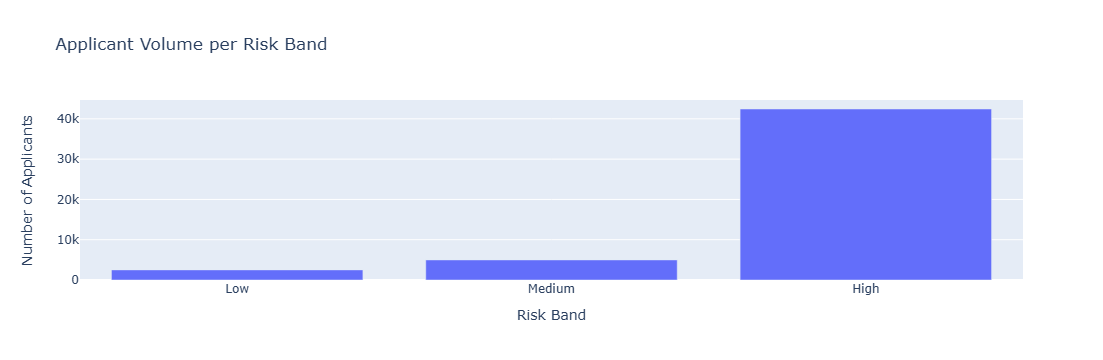

In [444]:
risk_band_counts = df['Risk_Band'].value_counts().sort_index().reset_index()
risk_band_counts.columns = ['Risk_Band', 'Number of Applicants']

fig = px.bar(
    risk_band_counts,
    x='Risk_Band',
    y='Number of Applicants',
    title='Applicant Volume per Risk Band',
    
)

fig.update_layout(
    xaxis_title='Risk Band',
    yaxis_title='Number of Applicants'
)

fig.show()

The bar chart displays the distribution of applicants across predefined risk bands—Low, Medium, and High—based on their predicted probability of default (PD). It is evident that the vast majority of applicants fall into the High-risk category, while only a small portion are classified as Medium-risk, and an even smaller fraction as Low-risk. This skewed distribution reflects the fact that the model predicts relatively high PD values for most individuals, possibly due to data imbalance or conservative calibration. For business strategy, this suggests that strict risk-based rejection policies might significantly reduce loan approvals unless thresholds are carefully reconsidered or the model is recalibrated for finer segmentation.

#### 9.4.3 Expected loss vs decision threshold

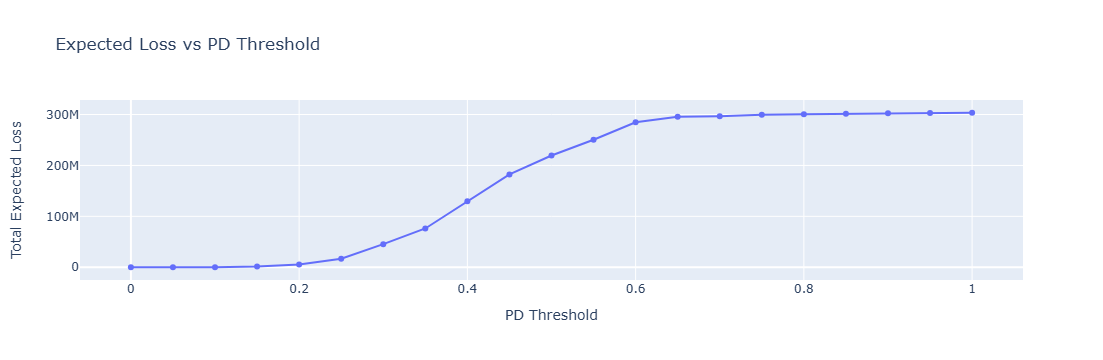

In [445]:
thresholds = np.arange(0, 1.01, 0.05)
losses = []

for t in thresholds:
    selected = df[df['PD'] <= t]
    total_loss = selected['Expected_Loss'].sum()
    losses.append(total_loss)

plot_df = pd.DataFrame({
    'PD Threshold': thresholds,
    'Total Expected Loss': losses
})

fig = px.line(
    plot_df,
    x='PD Threshold',
    y='Total Expected Loss',
    markers=True,
    title='Expected Loss vs PD Threshold'
)

fig.show()

The "Expected Loss vs PD Threshold" plot illustrates how the total expected loss accumulates as the probability of default (PD) threshold increases. At lower thresholds (below 0.4), the total expected loss remains minimal, indicating that applicants with low PDs contribute little to overall credit risk. However, as the threshold surpasses 0.4, the expected loss rises sharply and eventually plateaus beyond 0.6. This curve implies that most of the risk is concentrated in higher-PD applicants. From a credit policy perspective, this supports rejecting or repricing loans for individuals above a moderate PD threshold to significantly reduce total expected loss without excluding too many applicants.

# 10. Recommendation

### 10.1 What credit policies should be updated?

The bank should consider adopting a risk-based pricing or rejection policy, particularly targeting applicants in the high-risk band (PD > 15%). These applicants show significantly higher expected losses and should either be rejected or offered loans at higher interest rates to compensate for the elevated risk.

### 10.2 What is the impact of the model on expected losses?

The model enables effective segmentation of applicants by credit risk. As shown in the "Expected Loss vs PD Threshold" plot, expected loss increases sharply beyond a PD threshold of ~0.4, and then stabilizes. This insight allows the bank to set cut-off thresholds to limit risk exposure, reducing total expected losses substantially if applied strategically.

### 10.3 How can the model be integrated into loan decision workflows?

The predicted PD scores can be directly used to automate loan approval, rejection, or pricing decisions. For example:

Low-risk (PD < 5%) → auto-approve with favorable terms

Medium-risk (5% ≤ PD ≤ 15%) → manual review or pricing adjustment

High-risk (PD > 15%) → reject or require collateral/additional checks

### 10.4 Is the PD model stable across different customer segments?

Yes. The PD vs Actual Default Rate per Decile plot confirms strong calibration, where predicted probabilities align closely with observed outcomes across deciles. This suggests model stability and reliability across different segments, supporting its use in production with minimal bias or drift.
